# Anomaly Detection: from a 2-D toy dataset to fraud and predictive maintenance

**Goal.** Compare unsupervised detectors (Isolation Forest, LOF, ECOD, GMM) and supervised models (decision tree, logistic regression, EasyEnsemble) on three datasets, with a strict, leakage-free protocol and an operational decision rule.

| Part | Dataset | Question |
|---|---|---|
| 1 | Mouse (500 points, 2-D) | How do IF and LOF behave, and how to pick a threshold without labels? |
| 2 | Credit Card fraud (284k transactions, 0.17 % fraud) | Best method to **maximise recall with precision ≥ 80 %**? |
| 3 | Credit Card | A method beyond the course: **EasyEnsemble** (+ ECOD, GMM) |
| 4 | AI4I 2020 predictive maintenance (3.4 % failures) | Does the winner transfer? Target: precision ≥ 90 % |
| 5 | Mouse / Credit Card | Robustness to a contaminated reference, and **SHAP** explanations |

**Key findings**
- **Mouse (toy data)**: IF and LOF both rank the anomalies well; the **threshold rule**, not the model, makes the difference.
- **Credit Card fraud**: a class-weighted logistic regression meets the target on the test set (**precision 0.88, recall 0.79**, 85 alerts). No unsupervised detector reaches 80 % precision.
- **EasyEnsemble** ranks frauds as well as the best models (test AP 0.72) but narrowly misses the precision target on test (0.77).
- **Predictive maintenance**: the fraud winner meets the 90 % precision target but catches only **6 % of failures**: a linear model does not transfer to non-linear failure mechanisms.
- **Robustness and SHAP**: contamination effects depend on how anomalies are simulated; SHAP shows that IF flags extremes in any direction, which is why atypical normal transactions become false alarms.

A shorter notebook focused on fraud detection is also available: [fraud_detection.ipynb](fraud_detection.ipynb).

**Contents:** [Part 1 – Mouse](#part1) · [Part 2 – Credit Card](#part2) · [Part 3 – EasyEnsemble](#part3) · [3bis – ECOD & GMM](#part3bis) · [Part 4 – AI4I](#part4) · [Part 5 – Robustness & SHAP](#part5)

**Protocol.** Stratified 60/20/20 split, transformations and resampling fitted on train only, every threshold and hyperparameter chosen on validation, test set used **once** with frozen models. All the logic lives in [`src/utils.py`](../src/utils.py); this notebook only calls it and comments the results.

---
<a id="part1"></a>

## Part 1 – Mouse dataset
### 1a. Loading, checks and evaluation labels

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import pandas as pd
import utils

utils.print_versions()

python 3.12.3 (Linux 7.0.0-38-generic)
numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | shap 0.54.1
seed: 42


The last 10 rows of the file are the reference anomalies. The label vector `y` is built **in file order, before any shuffling**. It is used **only for evaluation and plot colouring**, never to fit the unsupervised methods.

In [2]:
X, y = utils.mouse_load_and_check(utils.DATA_DIR / 'mouse.txt')

X: (500, 2) float64 | y: (500,) int64
NaN: 0 | counts (normal, anomalies): [490  10]


,count,mean,std,min,25%,50%,75%,max
x1,500.0,0.505892,0.191763,0.040555,0.328481,0.504702,0.681430,0.916030
x2,500.0,0.599706,0.156863,0.138940,0.469010,0.629494,0.735364,0.897028
y,500.0,0.020000,0.140140,0.000000,0.000000,0.000000,0.000000,1.000000


,x1,x2,y
0,0.456601,0.432806,0
1,0.611378,0.528625,0
2,0.450299,0.711606,0


,x1,x2,y
488,0.785691,0.681914,0
489,0.708267,0.761234,0
490,0.290950,0.855767,1
491,0.750068,0.897028,1
492,0.040555,0.507240,1
493,0.835162,0.138940,1
494,0.174740,0.363686,1
495,0.151506,0.876586,1
496,0.860308,0.633833,1
497,0.862083,0.591805,1


**Result.** 500 points × 2 features (`x1`, `x2`, between 0 and 1), no missing values; 490 normal points and **10 anomalies (2 %)**, located on the last 10 rows as expected. With so few anomalies, every metric is very sensitive to 1 or 2 points.

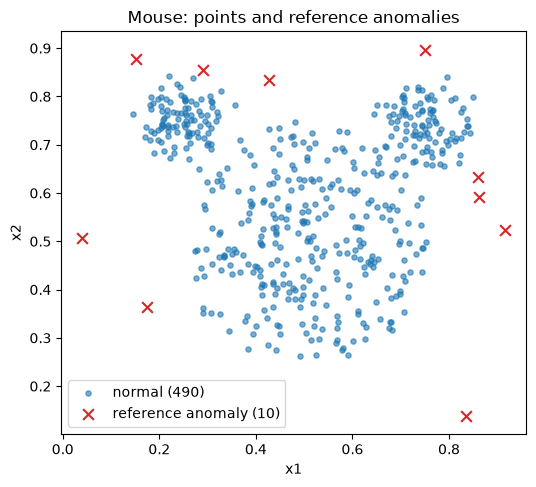

In [3]:
utils.plot_mouse(X, y); plt.show()

**Reading.** The shape is a cartoon mouse head: a large disc (face) and two small dense discs (ears). The 10 anomalies (red crosses) lie outside these areas and are of two kinds:
- **far from everything** (e.g. x1 ≈ 0.04 or x2 ≈ 0.14): easy to detect;
- **close to an ear** (x2 ≈ 0.85-0.9): abnormal only relative to the local density, hence harder.

### 1b. Isolation Forest and LOF on Mouse (outlier detection)
Both methods are fitted on **all 500 points, without labels**. Scores are harmonised: **higher = more suspicious** (IF's `score_samples` and LOF's `negative_outlier_factor_` are flipped). "Default" threshold = the one used by `predict` / `fit_predict` (`contamination='auto'`).

In [4]:
res_if, res_lof = utils.fit_mouse_methods(X, y)

IF: mean score normal = 0.480 | anomalies = 0.645 | flagged by default = 125 | fit time = 109 ms
LOF: mean score normal = 1.050 | anomalies = 2.407 | flagged by default = 10 | fit time = 3 ms


**Result (default threshold).**
- **Correct sign**: anomalies have a higher mean score than normal points for both methods (IF 0.645 vs 0.480; LOF 2.41 vs 1.05).
- **IF flags 125 points (25 % of the data)**: its default threshold is far too permissive here. **LOF flags exactly 10.**
- Scales differ: IF gives a score in ]0, 1[ (≈ 0.5 = normal), LOF a ratio (≈ 1 = normal density, ≫ 1 = isolated). Run times are negligible (a few ms).

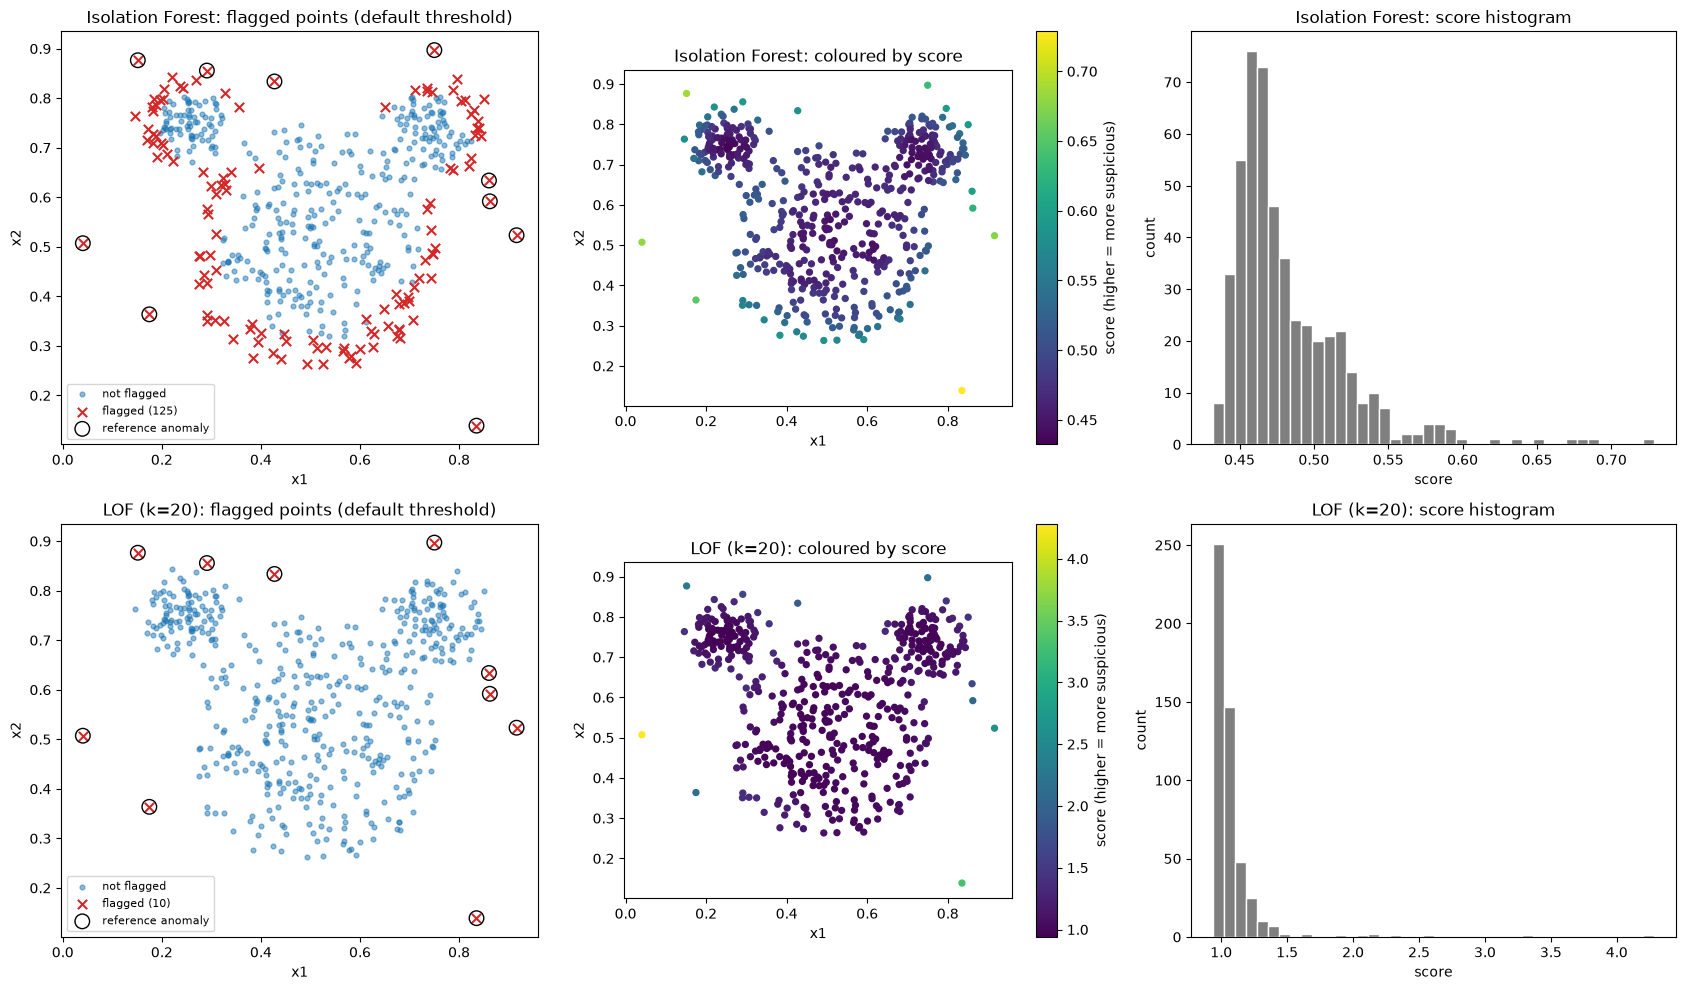

In [5]:
utils.plot_mouse_methods(X, y, res_if, res_lof); plt.show()

**Reading (top = IF, bottom = LOF; black circle = reference anomaly).**
- **Flagged points**: IF flags the 10 anomalies but also **115 normal points**, mostly on the edges of the shape: it measures *global eccentricity*. LOF flags only the 10 anomalies: it compares a point's density with that of its neighbours, so a point on the edge (same density as its neighbours) keeps LOF ≈ 1.
- **Colour by score**: a smooth gradient towards the edges for IF; for LOF, almost everything is ≈ 1 and only the anomalies stand out (up to ≈ 4).
- **Histograms**: IF has a spread-out distribution with no clear cut (hence a poorly placed default threshold); LOF is concentrated around 1 with a few isolated values on the right.

**In short**: both methods rank the anomalies at the top; the **threshold** makes the difference (good for LOF, bad for IF).

**LOF: training score or novelty score?** `negative_outlier_factor_` (`novelty=False`) gives the score of the training points, each point being excluded from its own neighbourhood. `score_samples` (`novelty=True`) is meant for **new** points: applied to training points, each point counts itself as a neighbour. Both are compared on the same points, for illustration.

rank correlation (Spearman): 0.995
mean |train - novelty| gap: 0.01


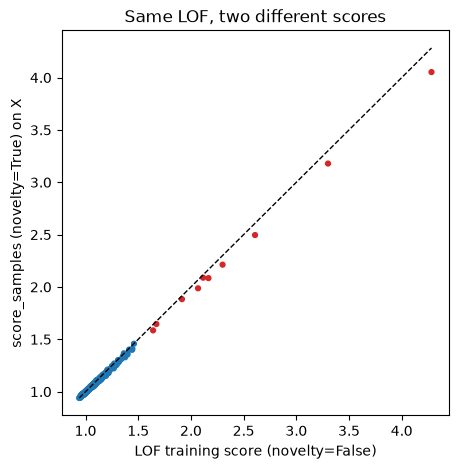

In [6]:
utils.compare_lof_scores(X, y, res_lof); plt.show()

**Result.** Both scores rank almost identically (Spearman 0.995, mean gap 0.01), but the anomalies sit slightly **below** the diagonal: in novelty mode the point counts itself as its own neighbour (distance 0), its area looks denser and its score drops (≈ 4.05 vs ≈ 4.3 for the most extreme one). **Rule**: `negative_outlier_factor_` for training points, `score_samples` only for unseen points.

### 2. Choosing a threshold without labels
**2a. IQR rule (Tukey).** On the scores only: threshold = `Q3 + k·IQR` (only the upper bound matters, since higher = more suspicious). `k` is fixed **a priori**, without looking at the labels: **1.5** ("outlier") and **3** ("extreme outlier"). It is a heuristic and does not guarantee the best threshold.

**2b. Comparison** with the default threshold: flagged points, confusion matrix, **F1 of the anomaly class** (main metric).

In [7]:
rules, tables = utils.mouse_threshold_study(X, y, res_if, res_lof)

=== IF ===


,threshold,alerts,TN,FP,FN,TP,precision,recall,F1,bal. acc.
rule,,,,,,,,,,
default,0.500,125,375,115,0,10,0.080,1.0,0.148,0.883
IQR k=1.5,0.563,21,479,11,0,10,0.476,1.0,0.645,0.989
IQR k=3,0.625,6,490,0,4,6,1.000,0.6,0.750,0.800


=== LOF ===


,threshold,alerts,TN,FP,FN,TP,precision,recall,F1,bal. acc.
rule,,,,,,,,,,
default,1.500,10,490,0,0,10,1.000,1.0,1.000,1.000
IQR k=1.5,1.226,37,463,27,0,10,0.270,1.0,0.426,0.972
IQR k=3,1.367,18,482,8,0,10,0.556,1.0,0.714,0.992


**Reading the table** (F1 = main metric).
- **IF**: the default threshold (0.50) falls inside the bulk of the scores → 115 false alarms, **F1 0.15**. IQR moves the threshold into the tail: **F1 0.65** (k = 1.5: 11 false alarms, no missed anomaly) and **0.75** (k = 3: no false alarm but **4 missed anomalies**, the ones close to the face or between the ears).
- **LOF**: the default threshold (1.5) is already perfect (**F1 = 1**). IQR **degrades** it (F1 0.43 and 0.71): scores are tightly packed around 1, so the IQR is tiny and the threshold too low, catching normal points on the edges.
- **Conclusion**: IQR fixes a poorly calibrated threshold (IF) but can degrade a good one (LOF); its effect depends on the shape of the score distribution. With 10 anomalies, one more or one fewer changes recall by 10 points.

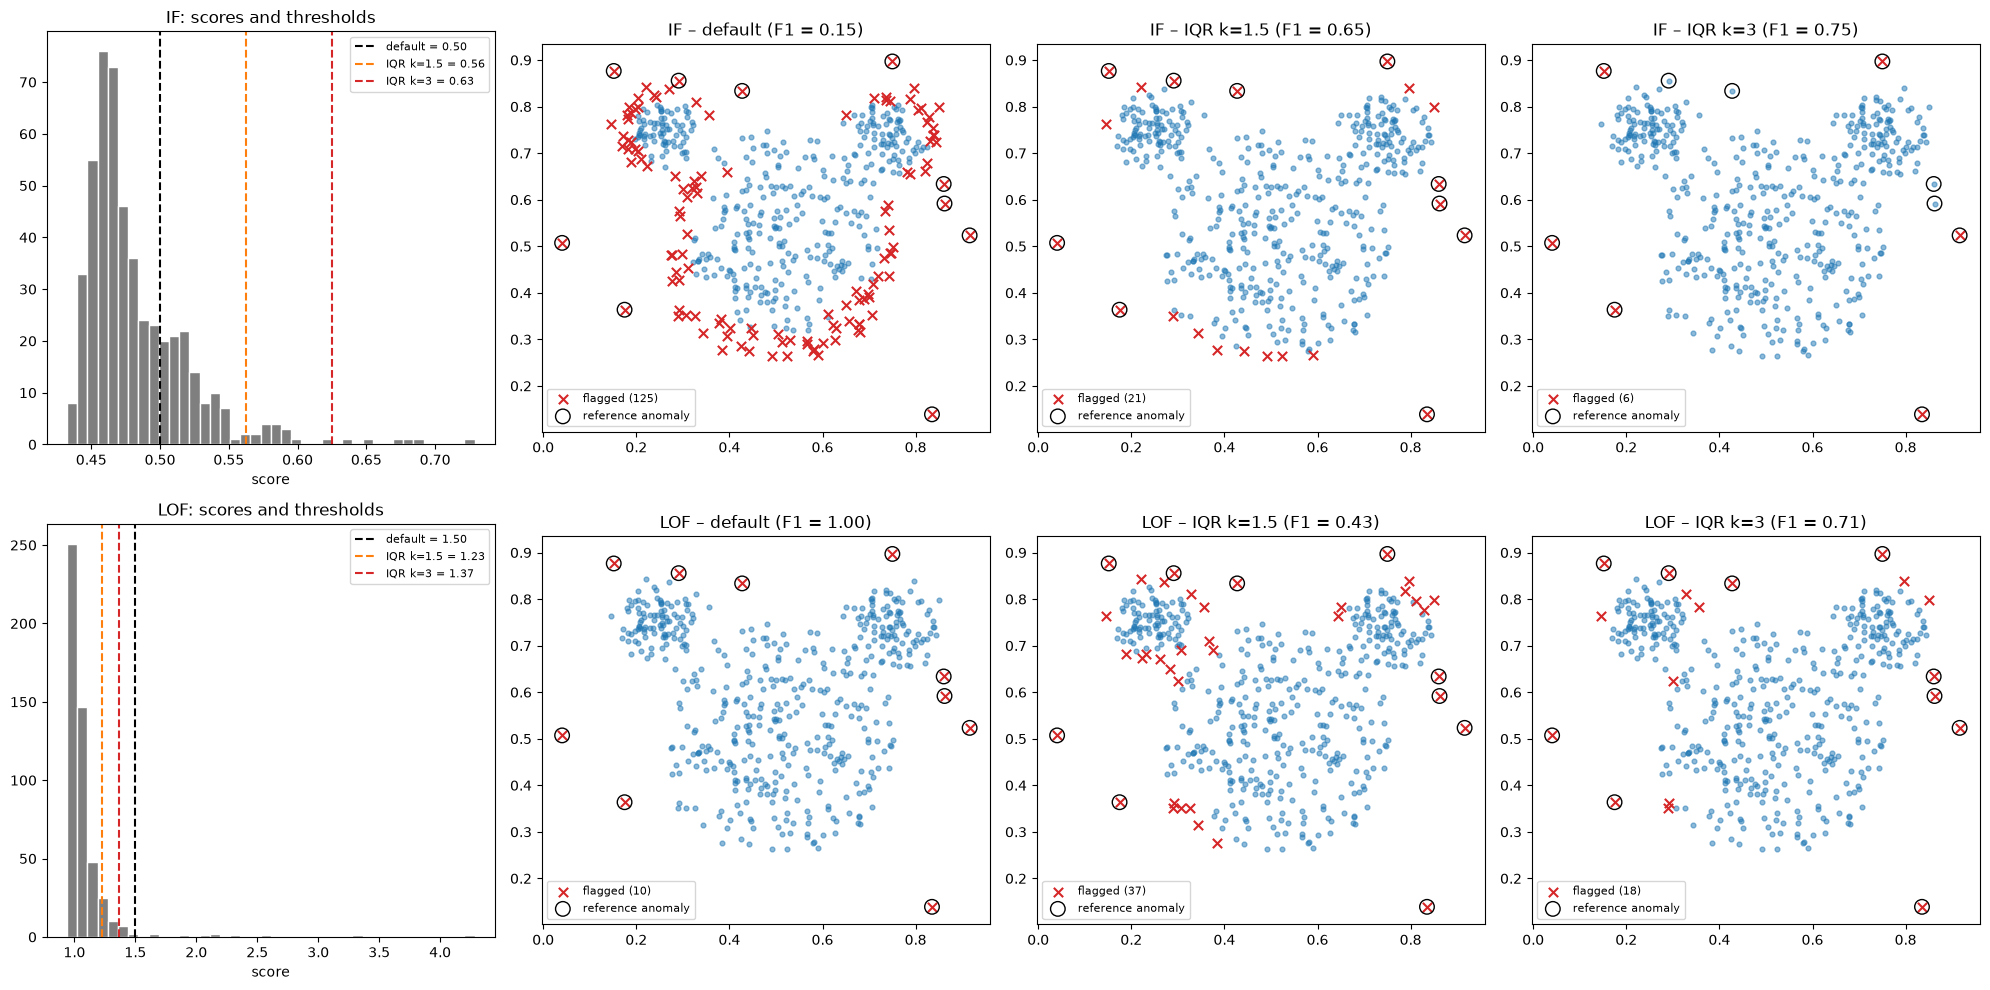

In [8]:
utils.plot_mouse_thresholds(X, y, res_if, res_lof, rules, tables); plt.show()

**Reading.** For IF, the IQR thresholds (0.56 and 0.63) lie in the tail of the histogram, far from the default: far fewer crosses on the edges; with k = 3 all crosses are correct but 4 circles are empty. For LOF, the three thresholds are very close (1.23 / 1.37 / 1.50): the IQR thresholds land at the edge of the bulk, hence false alarms in dense but irregular areas.

**2c. AP and ROC-AUC of the scores.**

In [9]:
rank = utils.mouse_ranking_table(y, res_if, res_lof)

,AP,AUC-ROC
IF,0.961,0.999
LOF,1.000,1.000


**Result.** LOF: AP = AUC = **1.0** (the 10 highest scores are the 10 anomalies). IF: AUC 0.999 but **AP 0.961**: a few normal points rank above some anomalies, which AP penalises more than AUC when positives are rare.

**Why changing the threshold changes neither AP nor AUC**: these metrics sweep *all* thresholds and only depend on the **order** of the scores. Changing the threshold just picks another point on the same curve: the confusion matrix and F1 change (IF: F1 from 0.15 to 0.75), the curve does not. We therefore separate the quality of the **ranking** (AP, AUC) from that of the **decision** (F1 after thresholding).

**Limitation**: scores are computed and evaluated on the same 500 points: this describes the observed sample, not an estimate on future data.

### 3. Moving to novelty detection
**3a. Protocol.** Separate test set = **the 10 anomalies + 20 % of the normal points** (fixed seed). LOF (`novelty=True`) is fitted **only on the remaining normal points**, then evaluated **only on the test set**. Thresholds set without looking at the test set: the `predict` threshold, and IQR (k = 1.5 and 3) computed on the training scores (`negative_outlier_factor_`).

In [10]:
novelty = utils.mouse_novelty_fit(X, y)

train: 392 normal points | test: 108 points = 98 normal + 10 anomalies
mean score: train 1.048 | test normal 1.079 | test anomalies 2.373
time: fit 1.7 ms | test scoring 0.7 ms


,threshold,alerts,TN,FP,FN,TP,precision,recall,F1,bal. acc.
rule,,,,,,,,,,
default (predict),1.500,14,94,4,0,10,0.714,1.0,0.833,0.980
IQR k=1.5,1.225,24,84,14,0,10,0.417,1.0,0.588,0.929
IQR k=3,1.368,16,92,6,0,10,0.625,1.0,0.769,0.969


,AP,AUC-ROC
LOF novelty (test),1.0,1.0


**Result.** Training: **392 normal points**; test: **108 points** (98 normal + 10 anomalies), disjoint (checked with `assert`).
- **Perfect ranking on the test set**: AP = AUC = 1.0 (on only 10 anomalies).
- Default threshold: **F1 0.83** (14 alerts: the 10 anomalies + **4 normal points**). A *new* normal point can fall into an area poorly covered by the training set, hence a slightly higher LOF.
- The IQR thresholds, computed on training scores tightly packed around 1, are too low: 14 and 6 false alarms (F1 0.59 and 0.77). No anomaly is missed.
- These F1 scores are not comparable with section 2: the anomaly rate of the test set is 9 % (10/108) vs 2 %.

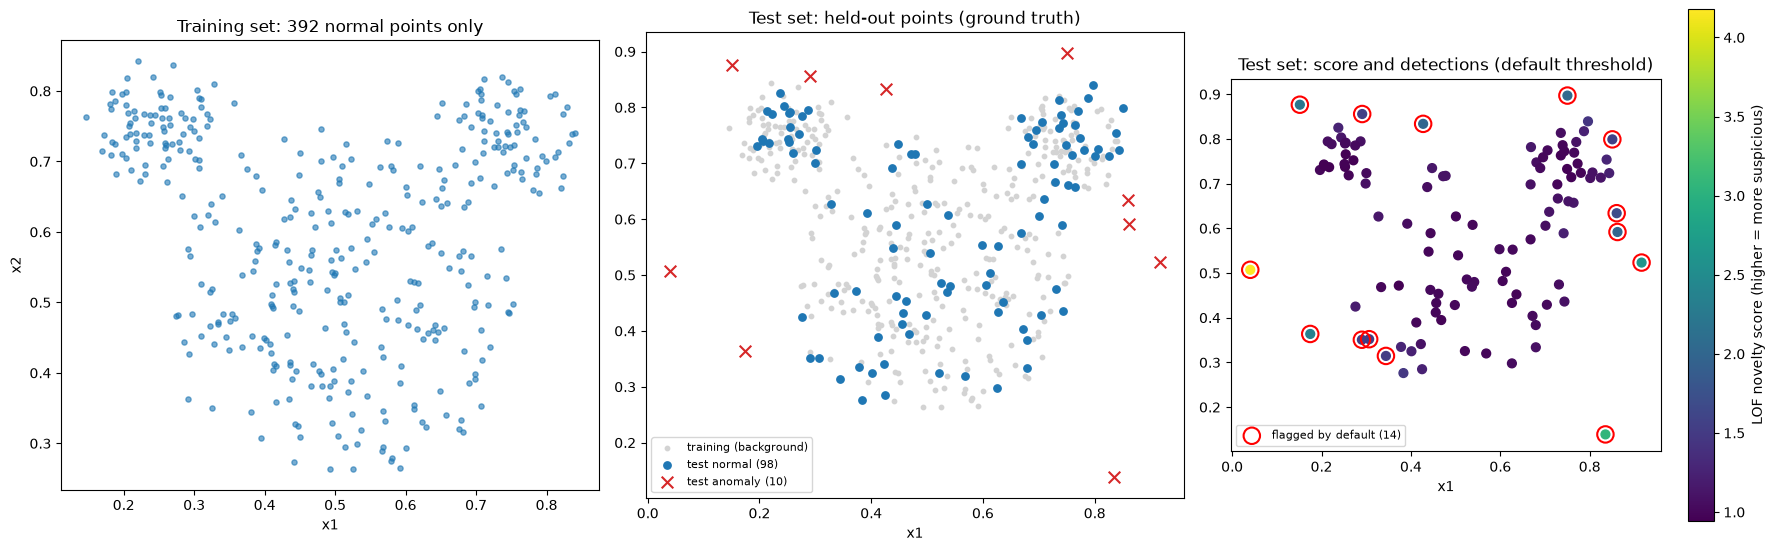

In [11]:
utils.plot_mouse_novelty(novelty); plt.show()

**Reading (left to right).** (1) Training set: the shape alone, without anomalies. (2) Test set: held-out normal points (blue) spread over the shape, anomalies (red) outside it. (3) Test set coloured by score: anomalies get the highest scores (up to ≈ 4.2); red circles mark the 14 alerts of the default threshold, including 4 normal points (3 at the bottom-left of the face, 1 in the right ear).

**3b. Outliers vs novelties: what changes.**

| | Outliers (`novelty=False`) | Novelties (`novelty=True`) |
|---|---|---|
| Training data | whole sample, **anomalies included** | only points **assumed normal** |
| Question | which points are atypical *in this dataset*? | does a **new** point look like the learned normal behaviour? |
| Score | `negative_outlier_factor_` | `score_samples` / `predict` on new points |
| Density reference | "polluted" by anomalies | clean |

**Using labels to build the training set changes the available information.** To get a 100 % normal training set, anomalies were removed using `y`. In practice this information only exists with a history already validated as normal: novelty detection therefore assumes **extra knowledge** that outlier detection does not use. This "pure" training set is optimistic (Part 5 studies a contaminated reference).

### IF vs LOF disagreements (same threshold rule)
For a fair comparison, the **same rule** (IQR, k = 1.5 then 3) is applied to both methods, and points flagged **by both**, **by IF only** and **by LOF only** are separated.

points  of which anomalies
rule      group                               
IQR k=1.5 both          17                  10
          IF only        4                   0
          LOF only      20                   0
IQR k=3.0 both           6                   6
          IF only        0                   0
          LOF only      12                   4

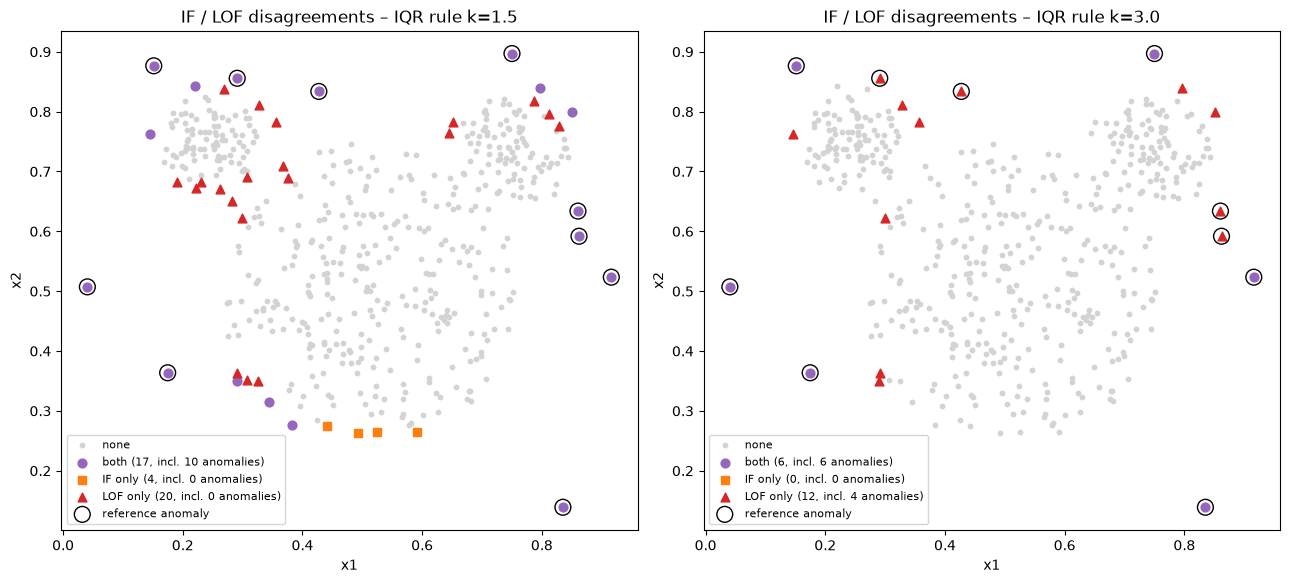

In [12]:
utils.plot_mouse_disagreement(X, y, res_if, res_lof); plt.show()

**Result.**
- **k = 1.5**: both methods find **all 10 anomalies in common**; they only disagree on false alarms (4 IF-only, 20 LOF-only, on the edges of the shapes).
- **k = 3**: IF's 6 alerts are also flagged by LOF; LOF adds 12, including **the 4 anomalies IF misses** and 8 normal points. IF is more conservative, LOF more sensitive.
- The IF vs LOF ranking therefore depends as much on the **threshold rule** as on the method (at the default threshold, LOF is perfect).

### Part 1 summary: IF / LOF disagreements and fragility
- **Agreement on the essentials**: LOF ranks the 10 anomalies 1st to 10th, IF ranks them 1-8, 10 and 14; their 20 most suspicious points share 14 points.
- **Disagreements**: (i) anomalies close to the ears (point (0.43, 0.83) is 14th for IF, 8th for LOF); (ii) normal points on the edges. IF measures how easy it is to *isolate* a point with axis-aligned cuts (global eccentricity); LOF compares local density with that of the neighbours and handles areas of different densities better (dense ears, sparser face).
- **Fragility**: one anomaly = 10 % of recall; a "perfect" AP only means that 10 points rank above 490. Parameters (100 trees, k = 20, IQR k) were not tuned, and section 3 relies on a single draw. These results describe the sample and do not generalise.

---
<a id="part2"></a>

# Part 2 – Fraud detection (Credit Card)
## 2.1 Preparing Credit Card
### Data inspection

> The dataset (`creditcard.csv`, 144 MB) is not stored in the repository: download it from [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) into `data/`.

In [13]:
df_raw = utils.creditcard_overview(utils.DATA_DIR / 'creditcard.csv')

shape: (284807, 31)
dtypes: {dtype('float64'): 30, dtype('int64'): 1}
missing values: 0
frauds: 492 / 284807 = 0.1727%  (1 in 578)


**Result.** 284,807 transactions × 31 columns (`Time`, `V1`..`V28`, `Amount`, `Class`), no missing values, **492 frauds (0.173 %)**, i.e. 1 in ≈ 578. Predicting "normal" everywhere would give 99.83 % accuracy without finding a single fraud: accuracy is useless, hence AP, precision and recall.

In [14]:
df = utils.creditcard_deduplicate(df_raw)

duplicated rows (all columns): 1081 | of which frauds: 19
duplicate groups with conflicting labels: 0


after removal: 283726 rows (1081 removed) | frauds: 473 (0.1667%)


**Result.** **1,081 rows are exact copies** (19 of them frauds), with no conflicting labels. They are **removed before splitting**: otherwise the same transaction could be in both train and test (data leakage, inflated performance). **283,726 rows remain, including 473 frauds (0.167 %)**.

### Stratified 60 / 20 / 20 split
Done after removing duplicates, and reused by every method. `Time` is excluded from the features (`CC_FEATURES` = V1..V28 + Amount) but kept to discuss the random split.

In [15]:
cc = utils.creditcard_split(df)   # dict: Xtr, ytr, Xva, yva, Xte, yte, ...

,transactions,frauds,fraud rate
train,170235.0,284.0,0.001668
validation,56745.0,94.0,0.001657
test,56746.0,95.0,0.001674


**Result.** The fraud rate is the same in the three partitions (≈ 0.167 %); `assert`s check that they are disjoint and share no identical row. **94 frauds in validation, 95 in test**: one fraud ≈ 1.1 % of recall, so differences of a few percent are not significant.

### Feature scales and preprocessing choice

**Scales (measured on the training set).** V1..V28 (PCA components) are centred, with standard deviations from 0.33 to 1.95 and **very heavy tails**. **Amount** is on a completely different scale: std 244, median 22, max 18,910, highly skewed.

**Preprocessing per family** (fitted on the training set only, then applied as is to validation and test).

| Family | Preprocessing | Why |
|---|---|---|
| LOF, logistic regression, SMOTE | `log1p(Amount)` + `StandardScaler` | distances and optimisation are scale-sensitive: otherwise `Amount` would dominate V1..V28; `log1p` reduces skewness |
| Decision tree, Isolation Forest | none | per-feature splits: insensitive to monotone transformations |

V1..V28 being anonymised, no domain-specific processing is possible; `RobustScaler` would be an alternative given the heavy tails.

### Limits of the random split: the Time variable

**Limit of the random split.** The dataset covers **48 h**. With a random split, a test transaction can precede a training transaction: the model "sees the future". In production we predict later transactions, with possible drift (frauds concentrated at certain hours). Results are therefore probably **optimistic**; a time-based split would be needed for real use.

## 2.2 Comparing methods and making a decision
### Supervised models: decision tree and logistic regression
**6 configurations per model** = 3 imbalance treatments × 2 values of one hyperparameter: tree `max_depth` ∈ {5, 10}; logistic regression `C` ∈ {0.01, 1}. Treatments: no correction, `class_weight='balanced'`, **SMOTE**.

**Why SMOTE?** RandomUnderSampler would throw away 99.7 % of the normal rows; RandomOverSampler duplicates the 284 frauds (overfitting); Tomek Links does not rebalance. SMOTE creates frauds by interpolating between neighbouring frauds. It is used with `sampling_strategy=0.1` (frauds = 10 % of normal rows, rather than 170,000 synthetic frauds), **after** scaling and **on the training set only** (a `Pipeline` step).

**Selection**: threshold chosen on **validation** (max recall subject to precision ≥ 80 %, ≥ 1 alert); configurations are ranked by target met, then recall, precision, AP.

In [16]:
MIN_PRECISION_FRAUD = utils.MIN_PRECISION_FRAUD   # constraint: precision >= 80 %
sup, res_sup = utils.run_supervised_grid(cc, MIN_PRECISION_FRAUD)

,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,t_fit (s)
config,,,,,,,,,,,
tree | none | max_depth=5,0.668,0.856,0.050,0.862,0.734,80,True,0.793,11,25,2.488
tree | none | max_depth=10,0.593,0.832,1.000,0.875,0.670,72,True,0.759,9,31,4.717
tree | class_weight | max_depth=5,0.434,0.888,0.999,0.560,0.745,125,False,0.639,55,24,2.447
tree | class_weight | max_depth=10,0.437,0.882,0.999,0.581,0.723,117,False,0.645,49,26,3.903
tree | smote | max_depth=5,0.664,0.938,0.989,0.845,0.755,84,True,0.798,13,23,2.895
tree | smote | max_depth=10,0.523,0.820,0.998,0.767,0.702,86,False,0.733,20,28,5.292
logreg | none | C=0.01,0.687,0.971,0.104,0.819,0.723,83,True,0.768,15,26,0.287
logreg | none | C=1.0,0.699,0.967,0.160,0.812,0.691,80,True,0.747,15,29,0.562
logreg | class_weight | C=0.01,0.674,0.962,1.000,0.835,0.755,85,True,0.793,14,23,0.560


**Reading the table (validation, 94 frauds).** `feasible=False` = target not met; the row then shows the best trade-off (max F1).
- **Logistic regression**: all 6 configurations meet the target (AP 0.67-0.70, AUC ≈ 0.96-0.97). The imbalance treatment barely changes the ranking, mostly the recall at the threshold (0.69 to 0.77).
- **Decision tree**: depth 10 is worse than 5 in every variant (overfitting on 284 frauds). With **class weighting, the target is not met** (precision ≤ 0.58): frauds weigh ≈ 600 times more, many leaves saturate at 0.999 and the threshold can no longer separate the frauds from the 49-55 false alarms.
- **No correction does not mean bad**: since the threshold is chosen on validation, the correction mainly affects the default threshold (0.5), which the rule replaces anyway.
- Differences of 0.01 to 0.03 between configurations = 1 to 3 frauds: not significant.

In [17]:
utils.print_resampling_sizes(sup, cc)

original training set: 170235 (frauds 284) | after SMOTE: 186946 (frauds 16995, normal 169951)
validation unchanged: 56745 (frauds 94) | test unchanged: 56746 (frauds 95)


**Sample sizes.** With SMOTE, the training set goes from 170,235 rows (284 frauds) to **186,946** (16,995 frauds, 10 %). Validation and test keep their natural imbalance.

In [18]:
best_sup = utils.best_per_family(res_sup, ['tree', 'logreg'])

,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
tree,tree | smote | max_depth=5,0.663899,0.93816,0.989201,0.845238,0.755319,84,True,13,23
logreg,logreg | class_weight | C=1.0,0.690599,0.961864,0.999994,0.8,0.765957,90,True,18,22


**Best configuration per model (validation).** Tree: SMOTE, depth 5 (precision 0.845, recall 0.755, 84 alerts). Logistic regression: weighted, C = 1 (precision **exactly 0.800**, recall 0.766, 90 alerts). The recall gap is only **one fraud** (72 vs 71), and the logistic regression meets the constraint right at the limit: to watch on the test set.

### Unsupervised detectors: Isolation Forest and LOF
- Fitted on the **training set as is** (normal and fraud mixed), **without labels or resampling**.
- **IF**: full training set (170,235 rows), raw features. **LOF** (expensive): **fixed stratified subsample of 30,000 rows**, scaled features, `novelty=True` to score validation and test (never to re-score the training set).
- **6 configurations each**: IF `n_estimators` ∈ {100, 300} × `max_samples` ∈ {256, 1024, 4096}; LOF `n_neighbors` ∈ {10, 20, 50, 100, 200, 500}.

**Fitting vs selection.** *Fitting* IF/LOF is unsupervised (`fit` sees no label). But **choosing** their hyperparameters and threshold with the validation labels is a **supervised selection**: validation performance is therefore optimistic, and only the test set, never used before the end, gives an honest estimate.

In [19]:
unsup, res_unsup, prep_scaled = utils.run_unsupervised_grid(cc, MIN_PRECISION_FRAUD)

LOF: subsample of 30000 rows incl. 50 frauds (0.167%) | IF: full training set 170235 rows


,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,F1@default,alerts@default,t_fit (s),t_score (s)
config,,,,,,,,,,,,,,
"IF | n_estimators=100, max_samples=256",0.112,0.941,0.629,0.175,0.362,194,False,0.236,160,60,0.072,1981,0.253,0.169
"IF | n_estimators=100, max_samples=1024",0.116,0.945,0.643,0.218,0.277,119,False,0.244,93,68,0.109,1102,0.367,0.163
"IF | n_estimators=100, max_samples=4096",0.136,0.945,0.578,0.190,0.426,211,False,0.262,171,54,0.162,624,0.410,0.180
"IF | n_estimators=300, max_samples=256",0.113,0.942,0.641,0.217,0.298,129,False,0.251,101,66,0.071,1997,0.617,0.441
"IF | n_estimators=300, max_samples=1024",0.119,0.945,0.643,0.205,0.277,127,False,0.235,101,68,0.109,1188,0.975,0.482
"IF | n_estimators=300, max_samples=4096",0.138,0.947,0.609,0.218,0.309,133,False,0.256,104,65,0.159,624,1.138,0.518
LOF | n_neighbors=10,0.003,0.536,2.183,0.016,0.064,384,False,0.025,378,88,0.005,3624,1.254,2.481
LOF | n_neighbors=20,0.014,0.665,2.000,0.046,0.181,371,False,0.073,354,77,0.023,2953,1.163,2.045
LOF | n_neighbors=50,0.162,0.948,2.481,0.302,0.415,129,False,0.350,90,55,0.051,2863,1.086,1.801


**Reading the table (validation).** LOF is fitted on 30,000 rows (50 frauds), IF on 170,235.
- **Target not met by any of the 12 configurations**: even with very few alerts, precision stays low (≤ 0.50 with at least 10 alerts, see below); the highest scores are often atypical normal transactions.
- **Misleading ROC-AUC**: ≈ 0.94-0.95 for IF and LOF (k ≥ 50), but AP of 0.11-0.14 (IF) and at most 0.34 (LOF): a few hundred normal rows ranked above the frauds are enough to ruin precision.
- **LOF depends strongly on k**: k = 10 and 20 are almost useless. Frauds form small clusters: with few neighbours, a fraud's neighbours are other frauds and it looks normal. The optimum is **k = 100 (AP 0.337)**.
- **IF**: barely sensitive to the number of trees; a larger `max_samples` helps a little (0.112 → 0.136).
- **Default thresholds unusable**: 624 to 1,997 alerts (IF), 2,844 to 4,164 (LOF), F1 ≤ 0.16.
- **Cost**: LOF scoring is the slowest (neighbour search, grows with k).

In [20]:
best_unsup = utils.best_per_family(res_unsup, ['IF', 'LOF'], pool=unsup, y_val=cc['yva'])

,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
IF,"IF | n_estimators=100, max_samples=4096",0.136114,0.944801,0.57846,0.189573,0.425532,211,False,171,54
LOF,LOF | n_neighbors=100,0.33706,0.94955,2.811944,0.433566,0.659574,143,False,81,32


IF (IF | n_estimators=100, max_samples=4096): max precision with >= 10 alerts = 0.364 (recall 0.085, 22 alerts)
LOF (LOF | n_neighbors=100): max precision with >= 10 alerts = 0.500 (recall 0.128, 24 alerts)


**Best configuration per detector (validation): target not met.** IF (100 trees, `max_samples` = 4096): AP 0.136, trade-off precision 0.19 / recall 0.43 (211 alerts). **LOF (k = 100)**: AP 0.337, precision 0.43 / recall 0.66 (143 alerts). LOF is clearly better, but both remain far behind the supervised models (AP 0.66-0.69): they do not use labels, and some frauds look like normal transactions.

### Overview of the 24 configurations
Colour = family (green tree, blue logistic regression, orange IF, red LOF). Left: AP; middle: precision and recall at the retained threshold (dot = target met, cross = not met); right: training time.

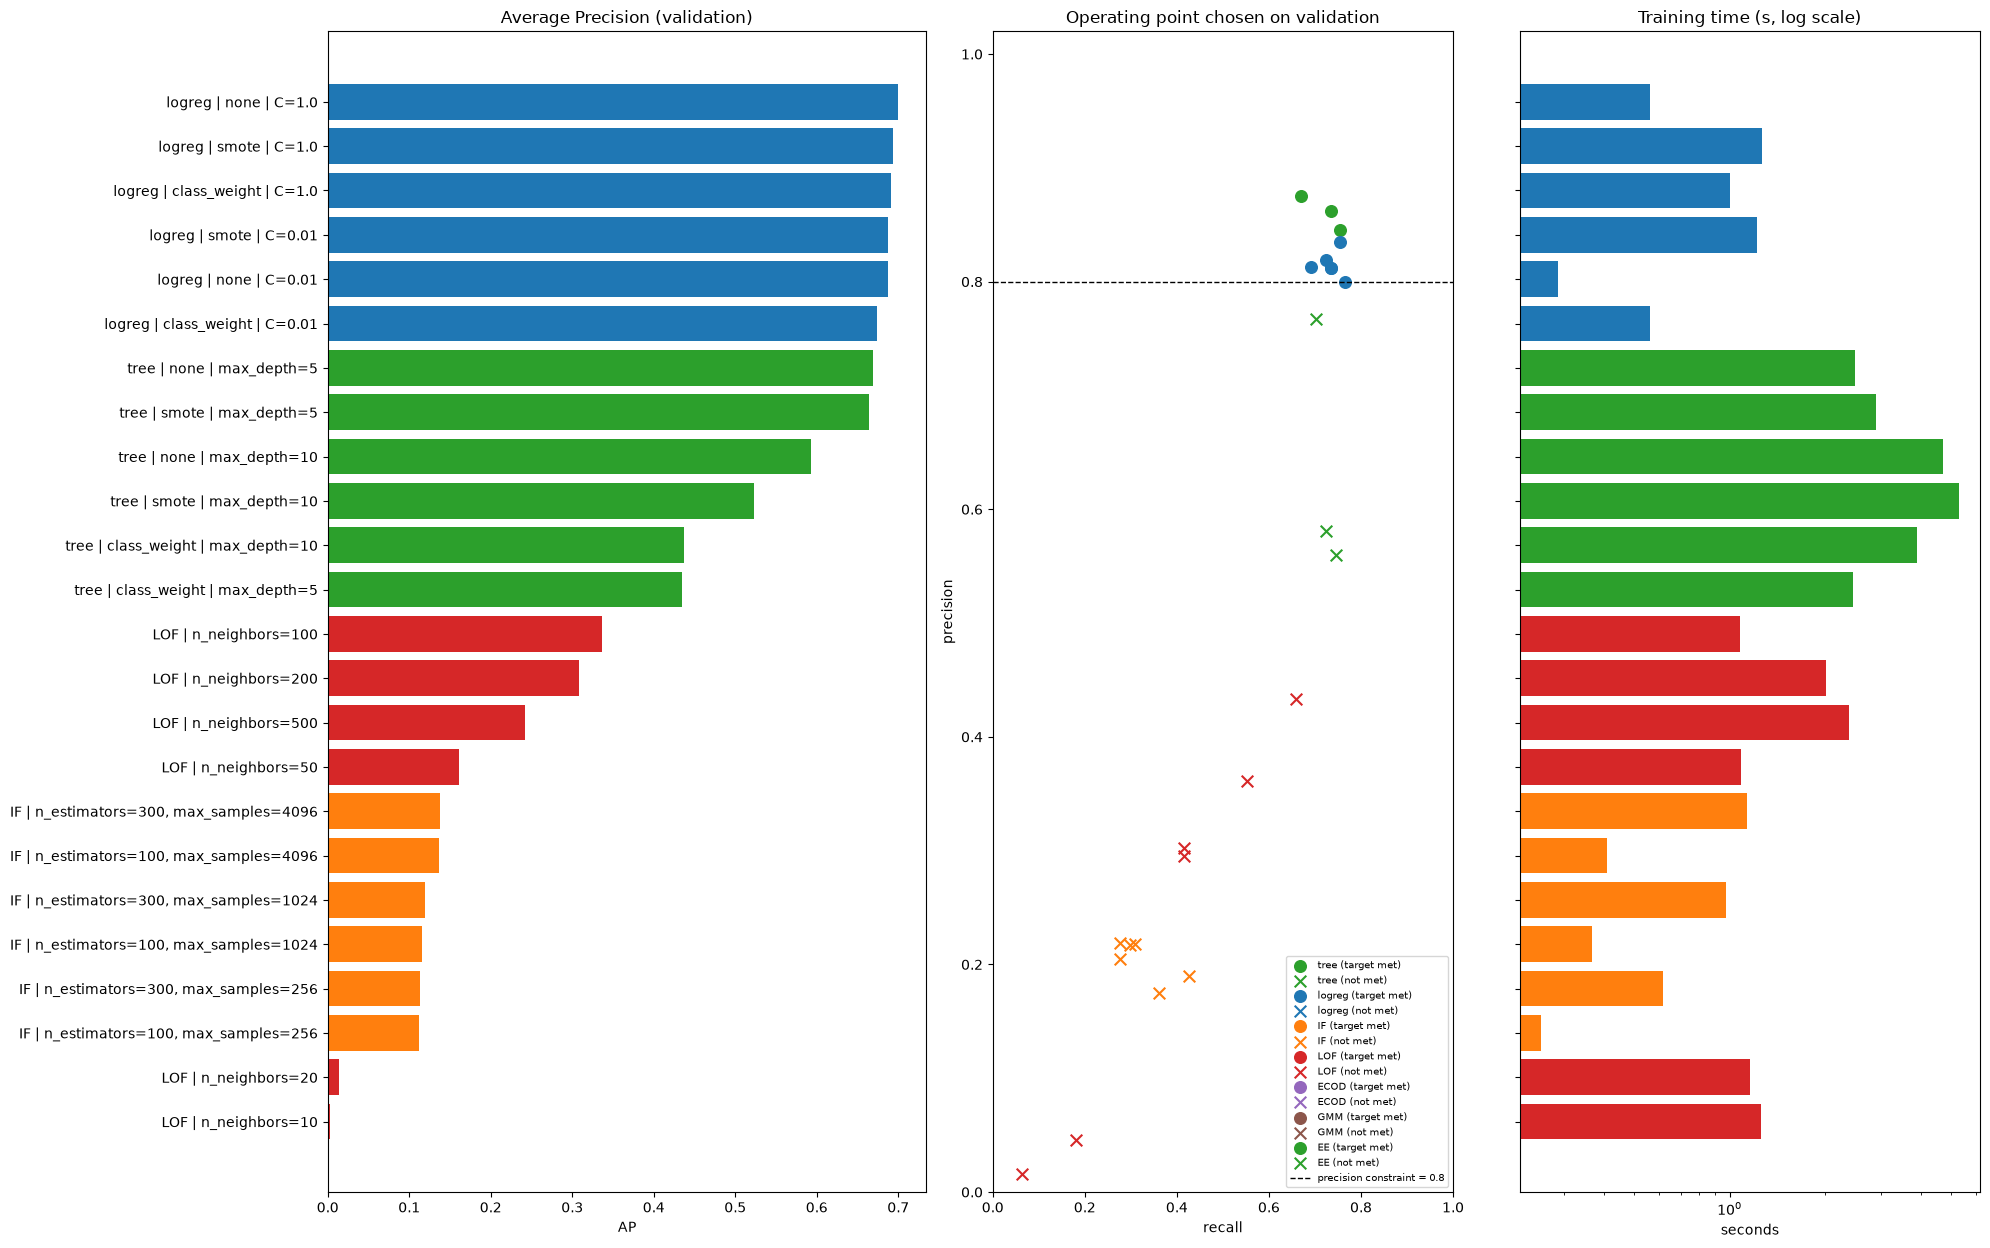

In [21]:
utils.plot_config_overview(pd.concat([res_sup, res_unsup])); plt.show()

**Reading.** Three AP groups: logistic regression and shallow tree (0.66-0.70) ≫ deep or weighted tree (0.43-0.59) ≫ LOF (≤ 0.34) and IF (≤ 0.14). Only supervised configurations are above the 0.8 precision line. All trainings take from a few tenths of a second to a few seconds.

### 2.3 ROC curves, precision-recall curves and thresholds (validation)
Comparison of the best configuration of each method.

Decision tree          -> tree | smote | max_depth=5
Logistic regression    -> logreg | class_weight | C=1.0
Isolation Forest       -> IF | n_estimators=100, max_samples=4096
LOF                    -> LOF | n_neighbors=100


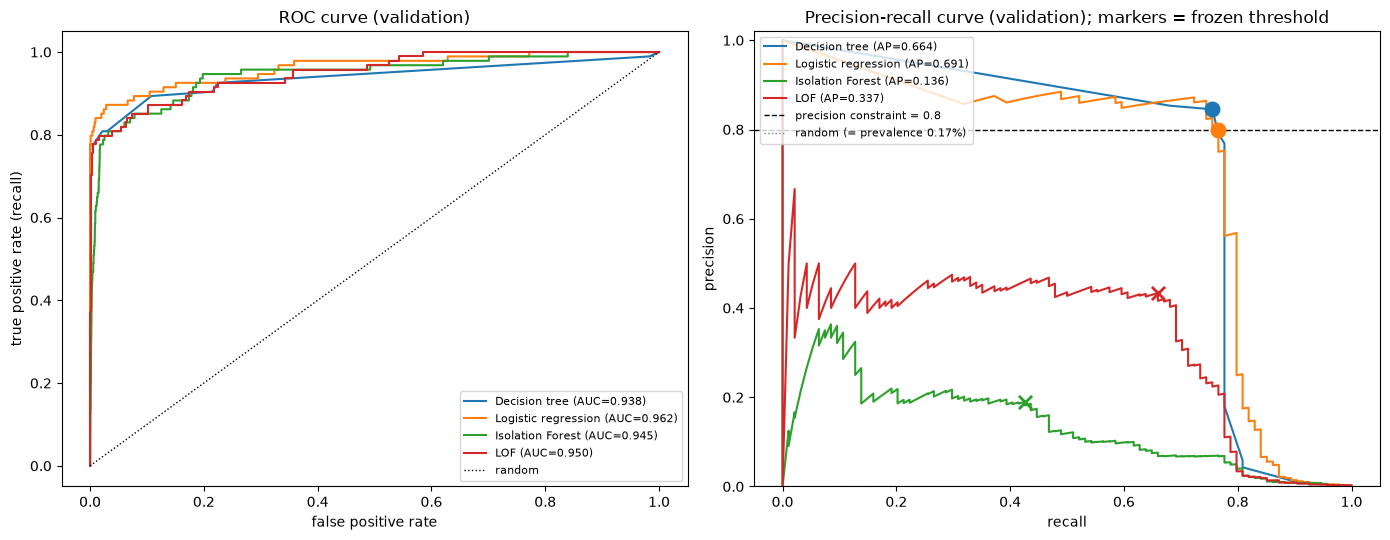

In [22]:
best_cfg, pool, scores_best, op_best = utils.collect_best_methods(best_sup, best_unsup, sup, unsup)
utils.plot_pr_roc(scores_best, cc['yva'], MIN_PRECISION_FRAUD, op_best); plt.show()

**Reading.**
- **ROC**: the four methods look close (AUC 0.94 to 0.96), because the false positive rate is diluted by 56,651 normal rows.
- **Precision-recall**: the differences show up. Logistic regression and tree keep a precision of 0.8-0.9 up to a recall of ≈ 0.75, then drop; LOF plateaus around 0.4-0.5 and IF around 0.2, always below the 0.8 line. The tree's curve is "stepped" (few distinct score values).

#### F1 and balanced accuracy as a function of the threshold
Horizontal axis = number of alerts. Vertical lines: max F1, max balanced accuracy, operating threshold.

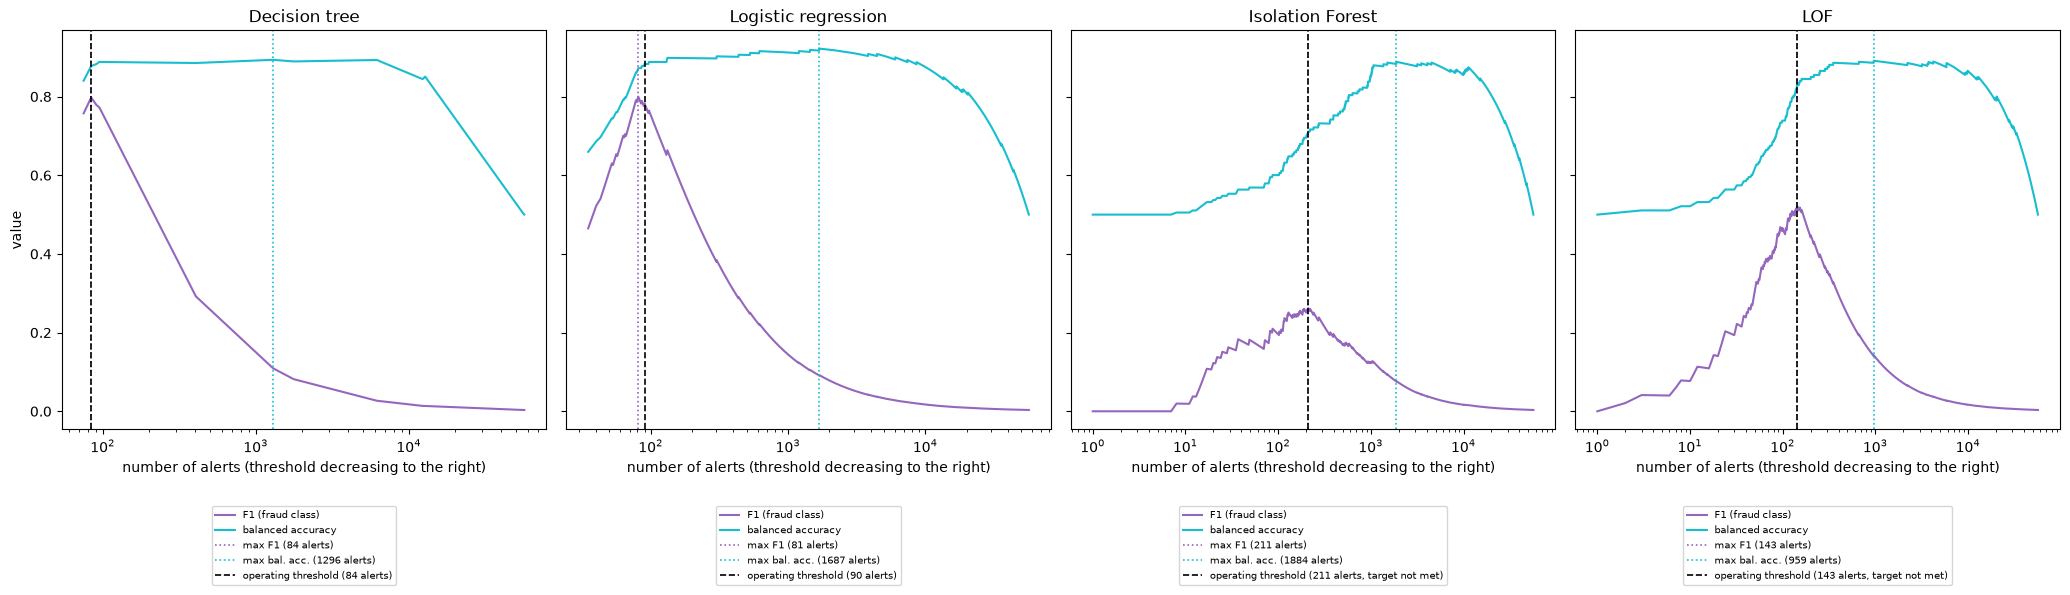

In [23]:
utils.plot_threshold_sweep(scores_best, cc['yva'], op_best); plt.show()

**Why these maxima do not match the operational target.**
- **F1** peaks around 81-84 alerts for the supervised models, close to the operating threshold but not identical (logistic regression: 81 vs 90 alerts): it is a *symmetric* precision/recall trade-off, whereas the target fixes precision first.
- **Balanced accuracy** peaks much further: **959 to 1,884 alerts**. As the mean of both class recalls, it costs little in normal-class recall (600 times more rows) and so pushes towards flagging a lot, for a precision of a few percent (tree: 5.9 %).
- Only the constraint-based threshold (precision ≥ 80 %) answers the business objective.

#### Score distribution per class

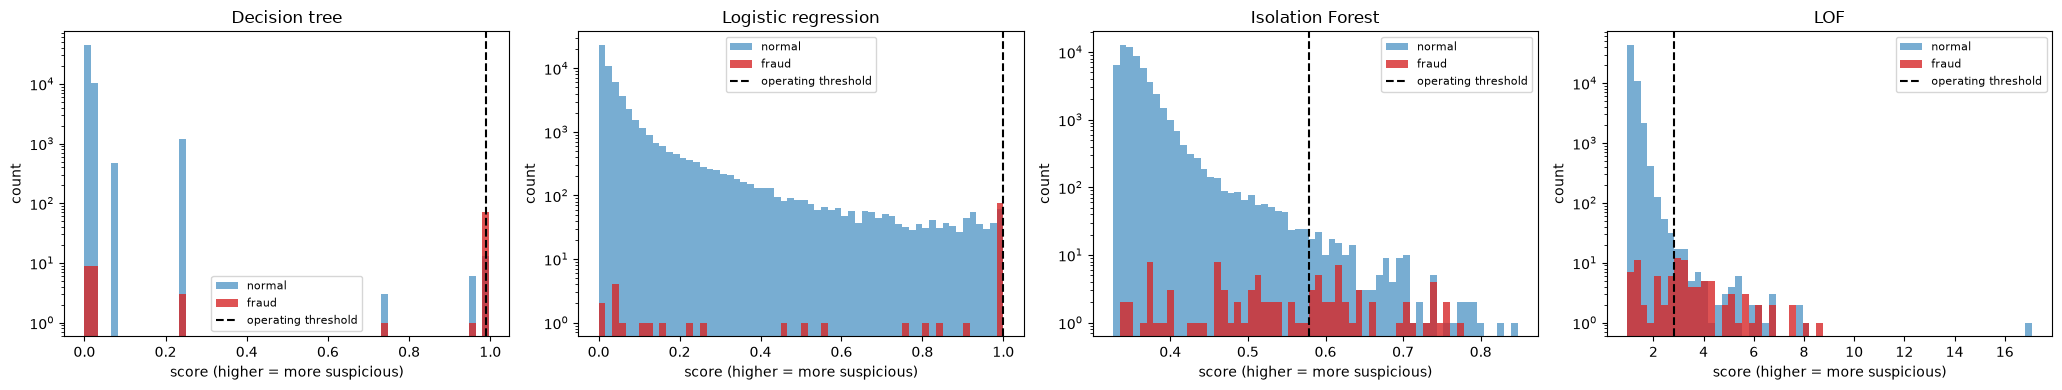

In [24]:
utils.plot_score_hist(scores_best, cc['yva'], op_best); plt.show()

**Reading (log scale).** Tree and logistic regression: most frauds are grouped near a score of ≈ 1, where there are very few normal rows (hence the precision); about twenty frauds have low scores, mixed with the normal rows: these are the missed frauds. IF and LOF: frauds are **spread across the tail of the normal distribution**, with no separate area. Supervised models learned a boundary; detectors only measure "atypicality", which normal transactions share too.

---
## 2.4 Evaluating scores and fixing the threshold
### AP and ROC-AUC on validation (recap)

,AP,AUC-ROC
Decision tree,0.664,0.938
Logistic regression,0.691,0.962
Isolation Forest,0.136,0.945
LOF,0.337,0.950


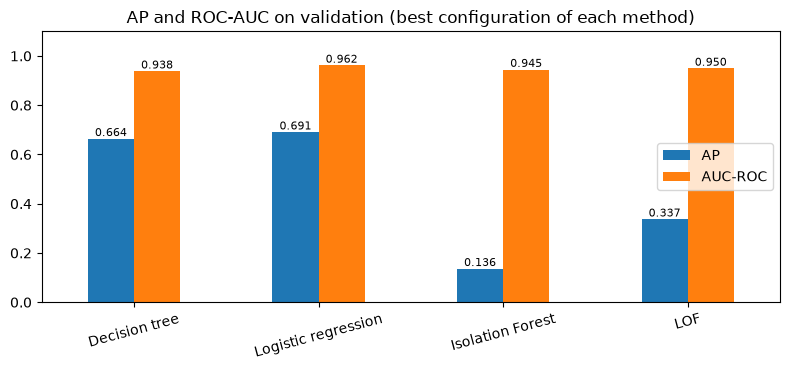

In [25]:
rows_val = op_best
utils.report_ap_auc(rows_val); plt.show()

**Result.** ROC-AUC is close for the four methods (0.94-0.96) and does not separate them; **AP** does: logistic regression (0.691) ≈ tree (0.664) ≫ LOF (0.337) ≫ IF (0.136). With 0.17 % fraud, AUC stays high even when hundreds of normal rows rank above the frauds, whereas AP drops: this is why AP is the main metric.

### Imposed rule: maximise recall subject to precision ≥ 80 %
Threshold retained on validation vs **default threshold** (0.5 for supervised models, `predict` for IF/LOF). The method is then **selected** (target met → recall → precision → AP) and model + threshold are **frozen before the test**.

,default threshold,alerts (default),precision (default),recall (default),F1 (default),retained threshold,alerts (retained),precision (retained),recall (retained),F1 (retained),target met
Decision tree,0.5,95,0.768421,0.776596,0.772487,0.989201,84,0.845238,0.755319,0.797753,True
Logistic regression,0.5,1482,0.054656,0.861702,0.102792,0.999994,90,0.8,0.765957,0.782609,True
Isolation Forest,0.5,624,0.092949,0.617021,0.16156,0.57846,211,0.189573,0.425532,0.262295,False
LOF,1.5,2844,0.026723,0.808511,0.051736,2.811944,143,0.433566,0.659574,0.523207,False


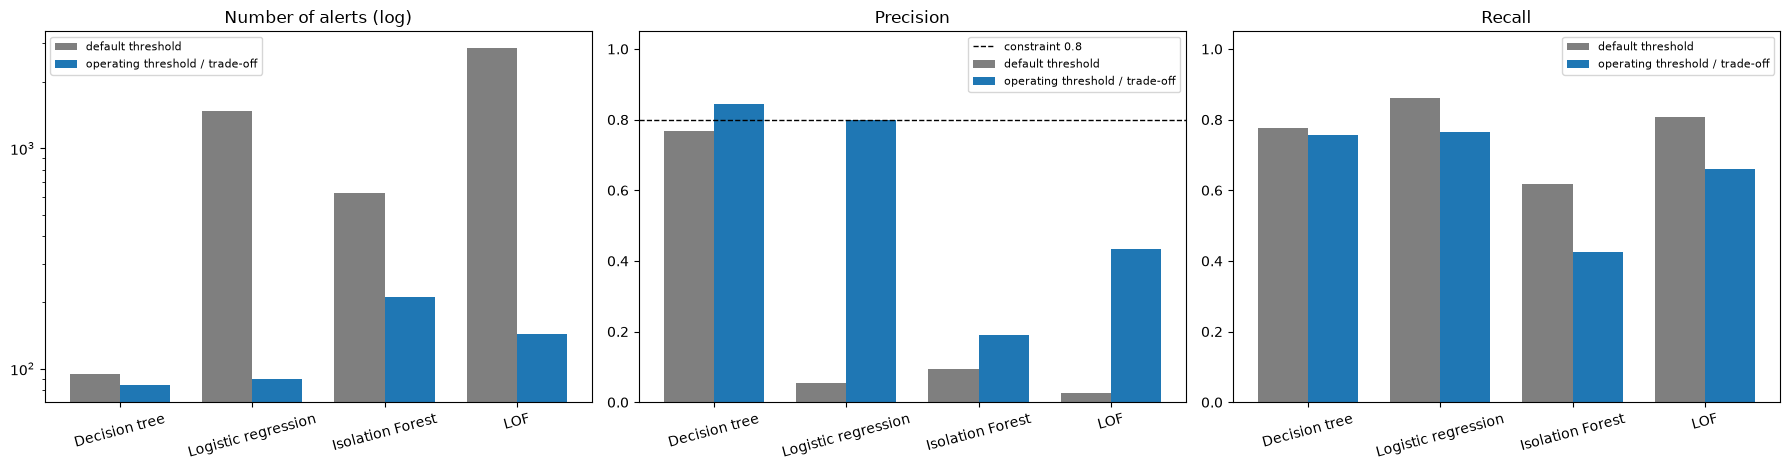

In [26]:
utils.report_default_vs_operational(rows_val); plt.show()

In [27]:
# selection on VALIDATION only (the test set has not been used yet)
SELECTED, FROZEN = utils.select_and_freeze(rows_val, best_cfg)

Method selected on validation: Logistic regression  (logreg | class_weight | C=1.0)
  frozen threshold = 0.999994 | validation: precision 0.800, recall 0.766, 90 alerts, target met = True


,config,threshold
Decision tree,tree | smote | max_depth=5,0.989201
Logistic regression,logreg | class_weight | C=1.0,0.999994
Isolation Forest,"IF | n_estimators=100, max_samples=4096",0.57846
LOF,LOF | n_neighbors=100,2.811944


**Result.**
- **Logistic regression**: at 0.5, **1,482 alerts** for 5.5 % precision (weighting inflates the probabilities); the retained threshold (0.999994) gives 90 alerts, precision 0.80.
- **Tree**: the default threshold is close (95 alerts) but its precision (0.77) is below 0.8; the retained threshold reaches it (0.845).
- **IF and LOF**: 624 and 2,844 alerts at the default threshold (precision < 10 %); target not met even at the retained threshold.

**Method selected on validation: weighted logistic regression (C = 1)**, recall 0.766 vs 0.755 for the tree (one fraud apart, so not statistically decisive). Model and threshold are frozen.

### Test-set evaluation (once, frozen models and thresholds)
Nothing is refitted. ★ = method selected on validation.

In [28]:
test_res, final = utils.evaluate_frozen_on_test(pool, FROZEN, SELECTED, rows_val, cc, prep_scaled, MIN_PRECISION_FRAUD)

,preprocessing,imbalance treatment / tuning,AP,AUC-ROC,frozen threshold,precision,recall,F1,bal. acc.,alerts,false alarms (FP),missed frauds (FN),fit time (s),test scoring time (s),constraint ≥ 0.8 met on test
method,,,,,,,,,,,,,,,
Decision tree,log1p(Amount)+StandardScaler (before SMOTE),"SMOTE (ratio 0.1), depth 5",0.650,0.895,0.989,0.804,0.779,0.791,0.889,92,18,21,2.895,0.010,True
★ Logistic regression,log1p(Amount)+StandardScaler,"class weighting, C=1",0.726,0.962,1.000,0.882,0.789,0.833,0.895,85,10,20,1.004,0.009,True
Isolation Forest,none,"none (unsupervised), 100 trees, max_samples=4096",0.237,0.955,0.578,0.201,0.442,0.276,0.720,209,167,53,0.410,0.193,False
LOF,log1p(Amount)+StandardScaler,"none (unsupervised), k=100, 30,000-row subsample",0.403,0.956,2.812,0.463,0.663,0.545,0.831,136,73,32,1.074,2.023,False


**Result – test set (56,746 transactions, 95 frauds).**

| Method | AP | AUC | Precision | Recall | F1 | Alerts | FP | FN | ≥ 0.8 |
|---|---|---|---|---|---|---|---|---|---|
| Decision tree (SMOTE) | 0.650 | 0.895 | 0.804 | 0.779 | 0.791 | 92 | 18 | 21 | yes (barely) |
| ★ **Logistic regression** | **0.726** | **0.962** | **0.882** | **0.789** | **0.833** | **85** | **10** | **20** | **yes** |
| Isolation Forest | 0.237 | 0.955 | 0.201 | 0.442 | 0.276 | 209 | 167 | 53 | no |
| LOF (k = 100) | 0.403 | 0.956 | 0.463 | 0.663 | 0.545 | 136 | 73 | 32 | no |

- The selected method is also the best on the test set. The tree barely meets the constraint; IF and LOF fail as on validation.
- The logistic regression's precision increase (0.80 → 0.88) is **sampling variability**, not a real improvement.
- **Cost**: training under 3 s; at scoring time LOF is by far the slowest (≈ 1.5 s vs ≈ 0.01 s for logistic regression), since it searches 100 neighbours per transaction.

#### Test-set plots
Confusion matrices, validation vs test precision and recall, test ROC and precision-recall curves (marker = frozen threshold).

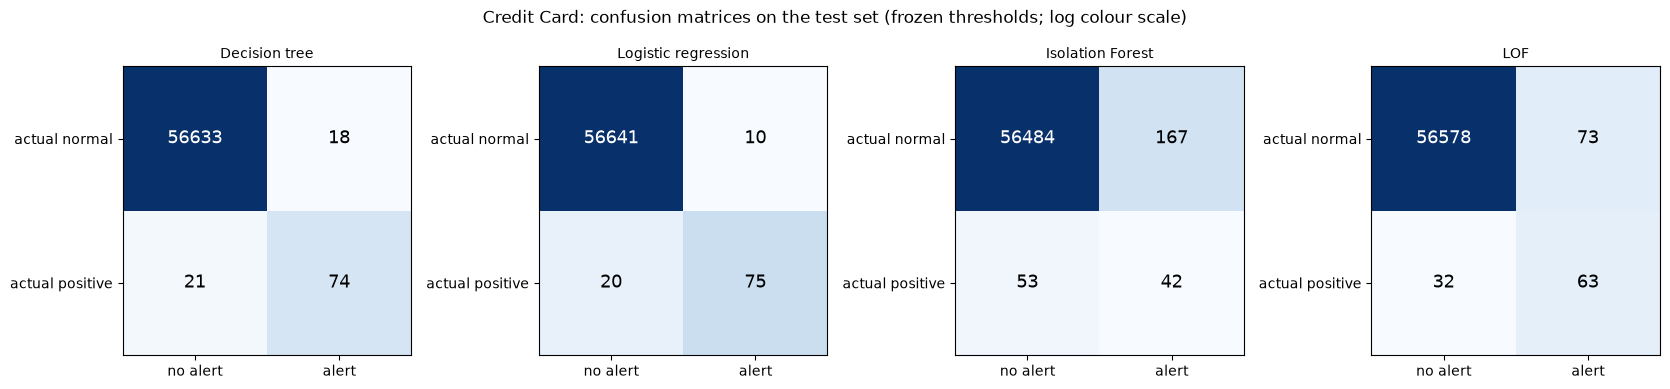

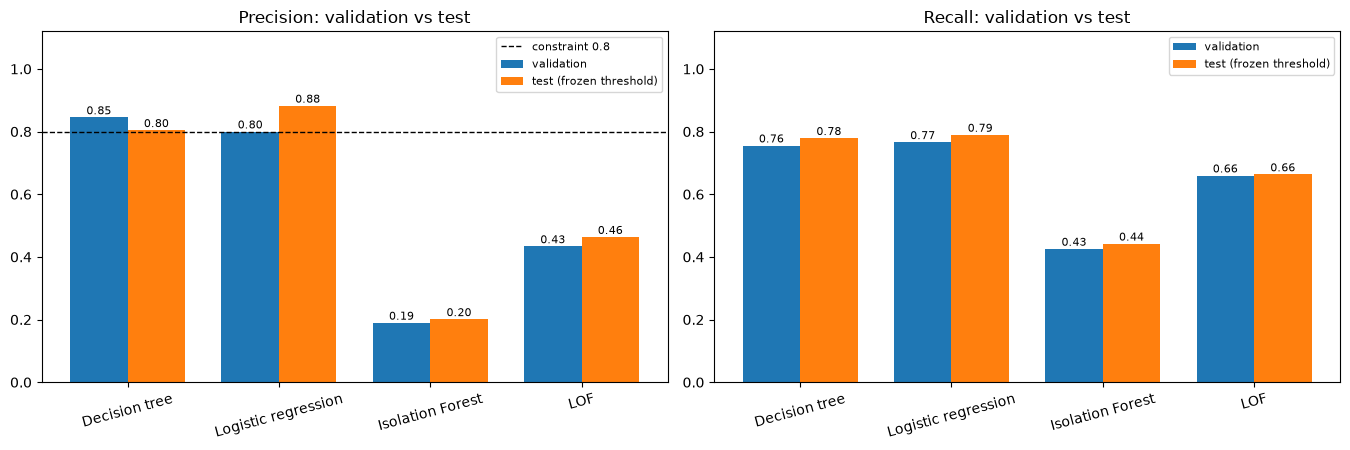

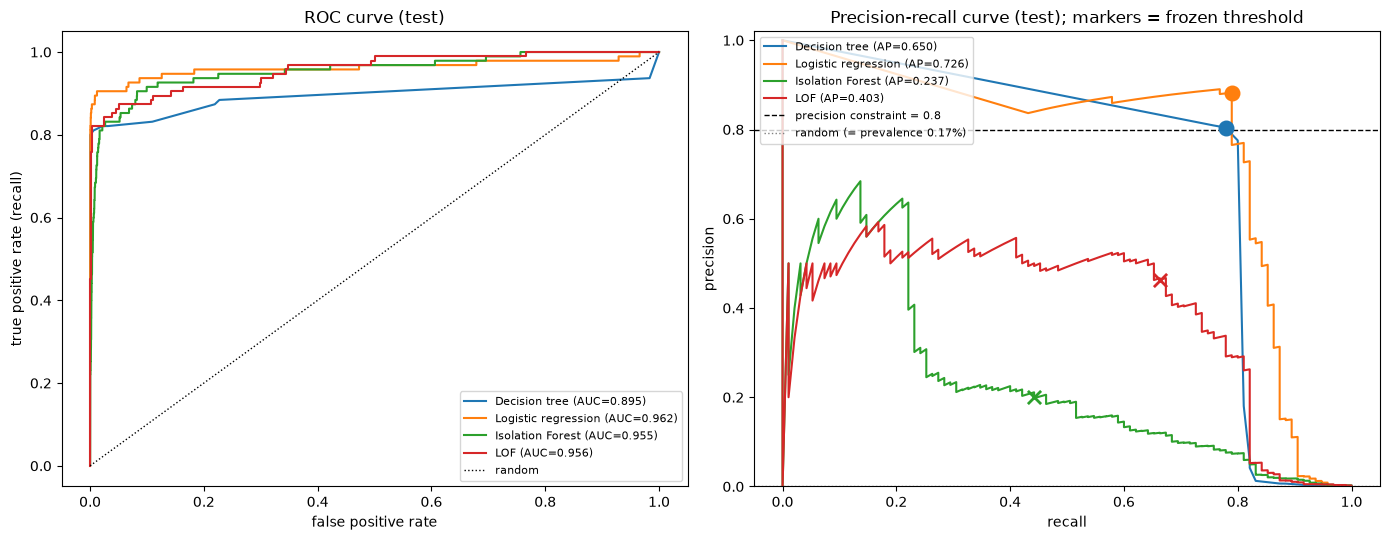

{'Decision tree': {'precision': 0.8043478260869565,
  'recall': 0.7789473684210526,
  'feasible': True},
 'Logistic regression': {'precision': 0.8823529411764706,
  'recall': 0.7894736842105263,
  'feasible': True},
 'Isolation Forest': {'precision': 0.20095693779904306,
  'recall': 0.4421052631578947,
  'feasible': False},
 'LOF': {'precision': 0.4632352941176471,
  'recall': 0.6631578947368421,
  'feasible': False}}

In [29]:
utils.report_test_graphs(test_res, rows_val, cc['yte'], MIN_PRECISION_FRAUD, subject='Credit Card')

**Reading.**
- **Matrices**: supervised models mostly err by **missed frauds** (20-21), detectors by **false alarms** (73 for LOF, 167 for IF).
- **Validation → test**: recall is very stable; supervised precision moves more (tree 0.85 → 0.80; logistic regression 0.80 → 0.88) because their thresholds sit at the edge of the constraint.
- **Curves**: the supervised markers lie just before a precision drop near a recall of 0.8: going further would break the constraint.

### Interpretation in number of transactions (selected method)

In [30]:
utils.report_selected_on_test(test_res, SELECTED, FROZEN, rows_val, MIN_PRECISION_FRAUD)

Test: 56746 observations incl. 95 positives (0.167%) | method: Logistic regression, frozen threshold 0.999994
- alerts to review: 85 (0.150% of observations) incl. 75 true frauds and 10 false alarms
- detected: 75 / 95; missed frauds: 20
- precision 0.882 (95 % Wilson CI: 0.797 - 0.935); recall 0.789 (95 % CI: 0.697 - 0.859)
- precision constraint >= 0.8 met on test: True | val -> test: precision 0.800 -> 0.882, recall 0.766 -> 0.789
- on average 1.13 alerts per true fraud


**Interpretation (logistic regression, frozen threshold 0.999994).**
- **85 alerts** to review out of 56,746 transactions: **75 frauds, 10 false alarms** (1.13 alerts per fraud found).
- **20 frauds out of 95 (21 %) go undetected.**
- Constraint **met** (0.882) without changing the threshold, but **fragile**: 95 % CI of precision [0.797, 0.935], whose lower bound is below 0.8.
- For comparison: IF would need 209 alerts for 42 frauds, LOF 136 for 63. Supervised models exploit the 284 labelled frauds; IF and LOF only measure atypicality.

**Limitations**: random split (results probably optimistic), a single split, ≈ 95 frauds per partition, anonymised features, and only one fraud between logistic regression and tree on validation.

---
<a id="part3"></a>

# Part 3 – Researching a new method: EasyEnsemble
**a) Choice.** *EasyEnsemble* is **not covered in the course** (SMOTE, Tomek, IF, LOF, PCA, One-Class SVM) nor among the imposed models. It is a **supervised** method for imbalanced data, compared here with IF and LOF. Two unsupervised methods beyond the course (ECOD, GMM) are tested further down as a complement.

**b) Source, principle, assumptions, score.**
- **Paper**: X.-Y. Liu, J. Wu, Z.-H. Zhou, *Exploratory Undersampling for Class-Imbalance Learning*, IEEE Trans. SMC Part B, 39(2):539–550, 2009. **Docs**: `imblearn.ensemble.EasyEnsembleClassifier`.
- **Principle**: *T* times, keep **all frauds** and draw **as many random normal rows** (≈ 568 balanced rows), then train an **AdaBoost** on this subsample. A single undersampling would discard almost all normal rows; by repeating it with different normal rows, the ensemble sees more of them and averaging reduces variance.
- **Score** = mean fraud probability over the *T* AdaBoost models (in [0, 1], higher = more suspicious).
- **Assumptions**: reliable labels; future frauds similar to training frauds; redundant normal rows (a small sample keeps the essentials). Probabilities are calibrated for a **balanced** dataset: the 0.5 threshold is unsuitable and must be chosen on validation.

**c) Why on Credit Card**: extreme imbalance; each model trains fast, **without synthetic data** or weighting. **Key hyperparameters**: the number *T* of subsamples and the number of AdaBoost stumps.

**d) Integration**: same partitions, same functions, same threshold rule on validation; **3 configurations** (*T*, AdaBoost) = (10, 50), (30, 50), (10, 200); test used once.

In [31]:
ee, res_ee = utils.run_easyensemble(cc, MIN_PRECISION_FRAUD)

,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,alerts@default,precision@default,t_fit (s),t_score (s)
config,,,,,,,,,,,,,,
"EasyEnsemble | bags=10, AdaBoost=50",0.669,0.962,0.654,0.800,0.723,85,True,0.760,17,26,1861,0.044,3.937,0.661
"EasyEnsemble | bags=30, AdaBoost=50",0.668,0.963,0.658,0.835,0.702,79,True,0.763,13,28,1884,0.043,2.377,1.447
"EasyEnsemble | bags=10, AdaBoost=200",0.660,0.961,0.607,0.800,0.681,80,True,0.736,16,30,1876,0.043,1.383,1.744


**Result (validation).**
- **Target met by all three configurations** (precision 0.80 to 0.835, recall 0.68 to 0.72). The retained configuration, (10, 50), meets it **exactly** (68 true alerts out of 85), which is fragile.
- **Barely sensitive to hyperparameters**: 10 or 30 subsamples give the same AP (0.669 / 0.668); 200 stumps do slightly worse (0.660), probably overfitting on small subsamples.
- **Default threshold unusable**: at 0.5, ≈ 1,870 alerts for 4.4 % precision.
- **Cost**: a few seconds of training; scoring slower than logistic regression (*T* × stumps must be queried).

In [32]:
best_ee = utils.best_per_family(res_ee, ['EE'])
p3_cfg, p3_scores, p3_op = utils.collect_detectors([best_ee, best_unsup], {**ee, **unsup})     # EasyEnsemble, IF, LOF
rows_p3 = {'EasyEnsemble': p3_op['EE'], 'Isolation Forest': p3_op['IF'], 'LOF': p3_op['LOF']}
for lab, cfg in p3_cfg.items(): print(f'{lab:4s} -> {cfg}')

,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
EE,"EasyEnsemble | bags=10, AdaBoost=50",0.669431,0.961638,0.653915,0.8,0.723404,85,True,17,26


EE   -> EasyEnsemble | bags=10, AdaBoost=50
IF   -> IF | n_estimators=100, max_samples=4096
LOF  -> LOF | n_neighbors=100


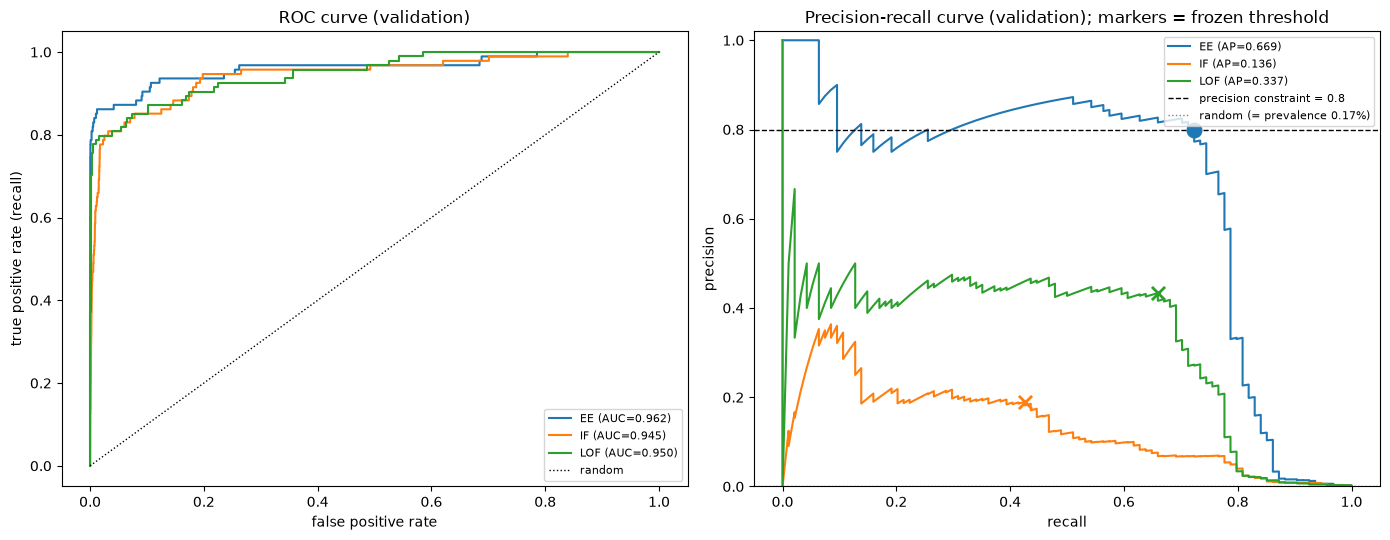

In [33]:
utils.plot_pr_roc(p3_scores, cc['yva'], MIN_PRECISION_FRAUD, p3_op); plt.show()

**Reading.** On ROC, the three methods are close (AUC 0.945 to 0.962). On precision-recall, EasyEnsemble is **far above** IF and LOF: precision 0.75-0.9 up to a recall of ≈ 0.75, while LOF plateaus around 0.45 and IF around 0.35. Its retained point (recall 0.72, precision 0.80) is **on the constraint line, at the edge of a precision drop**.

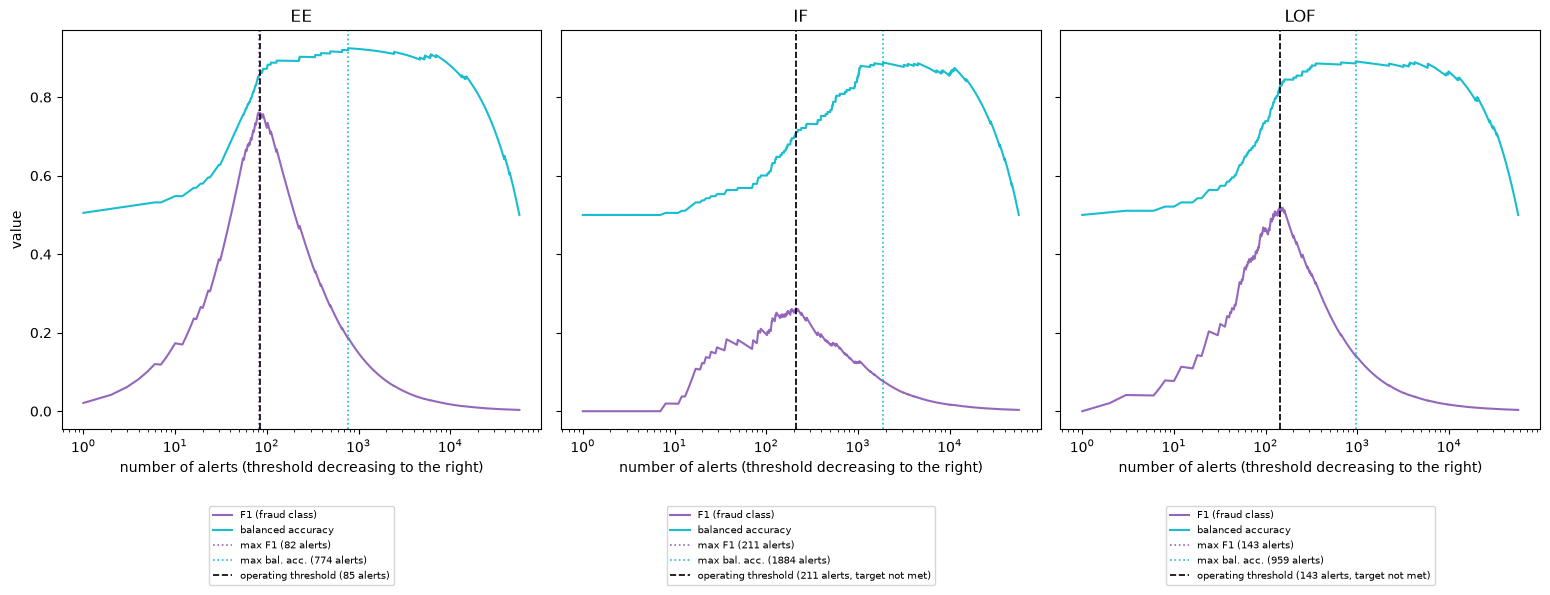

In [34]:
utils.plot_threshold_sweep(p3_scores, cc['yva'], p3_op); plt.show()

**Reading.** For EasyEnsemble, the max F1 (≈ 0.76, 82 alerts) is almost at the operating threshold (85 alerts). Balanced accuracy peaks at **774 alerts**, with a precision of a few percent: it ignores how reliable the alerts are.

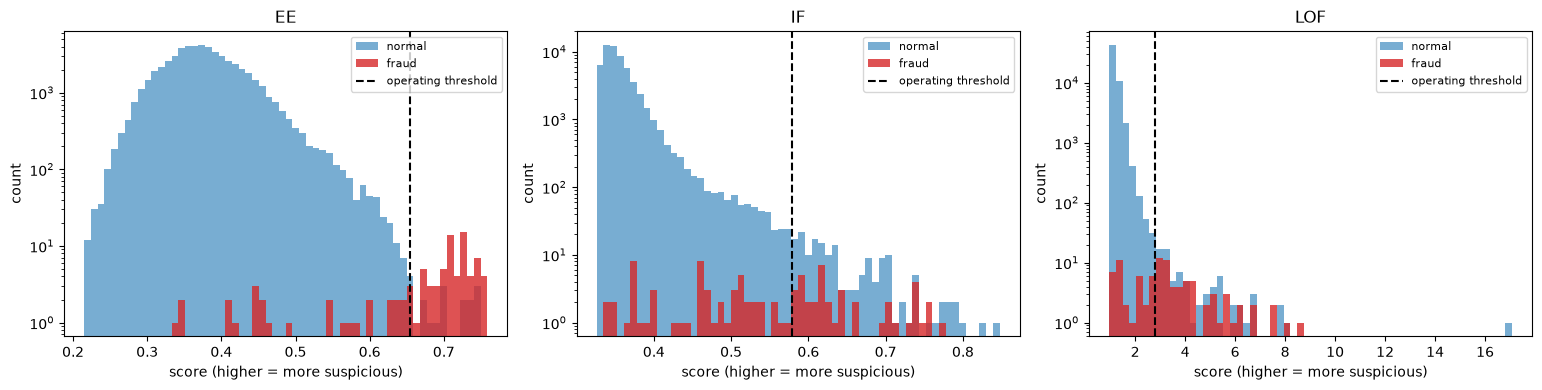

In [35]:
utils.plot_score_hist(p3_scores, cc['yva'], p3_op); plt.show()

**Reading (log scale).** EasyEnsemble puts most frauds above the threshold (0.65 to 0.76), where few normal rows remain; 26 frauds stay below, buried among normal rows. For IF and LOF, frauds are spread across the tail of the normal distribution. The difference comes from the labels, which EasyEnsemble uses.

,default threshold,alerts (default),precision (default),recall (default),F1 (default),retained threshold,alerts (retained),precision (retained),recall (retained),F1 (retained),target met
EasyEnsemble,0.5,1861,0.043525,0.861702,0.082864,0.653915,85,0.8,0.723404,0.759777,True
Isolation Forest,0.5,624,0.092949,0.617021,0.16156,0.57846,211,0.189573,0.425532,0.262295,False
LOF,1.5,2844,0.026723,0.808511,0.051736,2.811944,143,0.433566,0.659574,0.523207,False


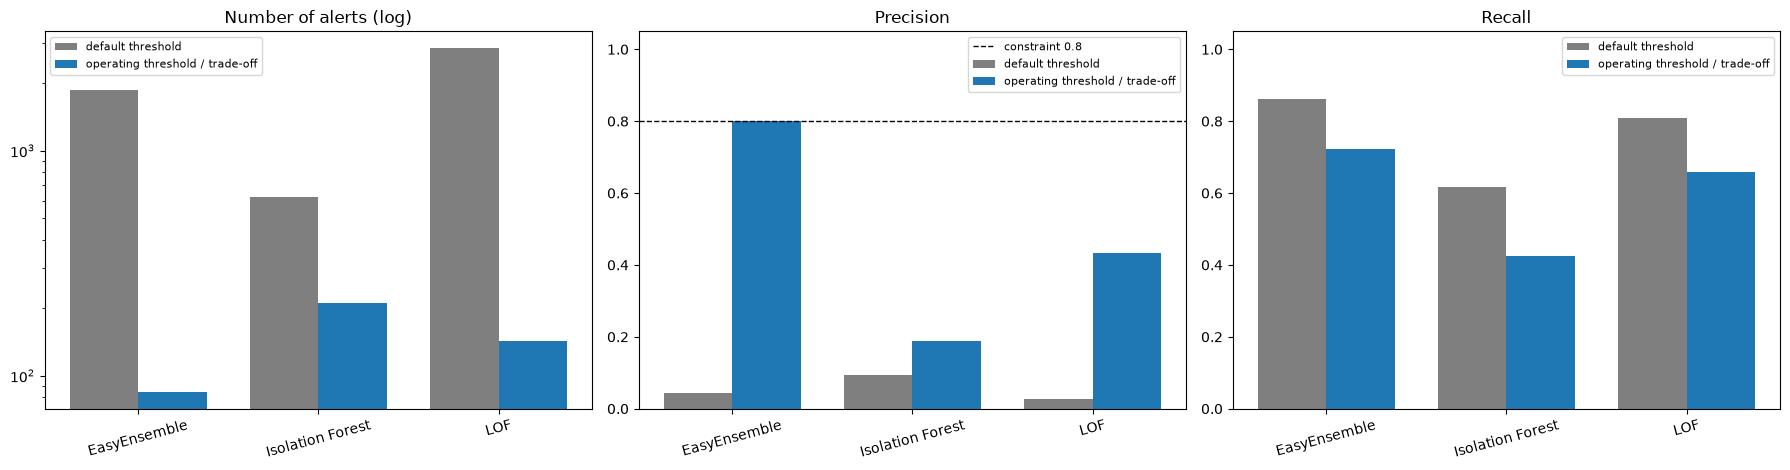

In [36]:
utils.report_default_vs_operational(rows_p3); plt.show()

**Result.** At 0.5, EasyEnsemble raises **1,861 alerts** (precision 4.4 %); the retained threshold (0.654) brings them down to **85** (precision 0.80, recall 0.72). IF and LOF stay below the constraint at both thresholds.

#### Comparison with the Part 2 supervised models (validation)

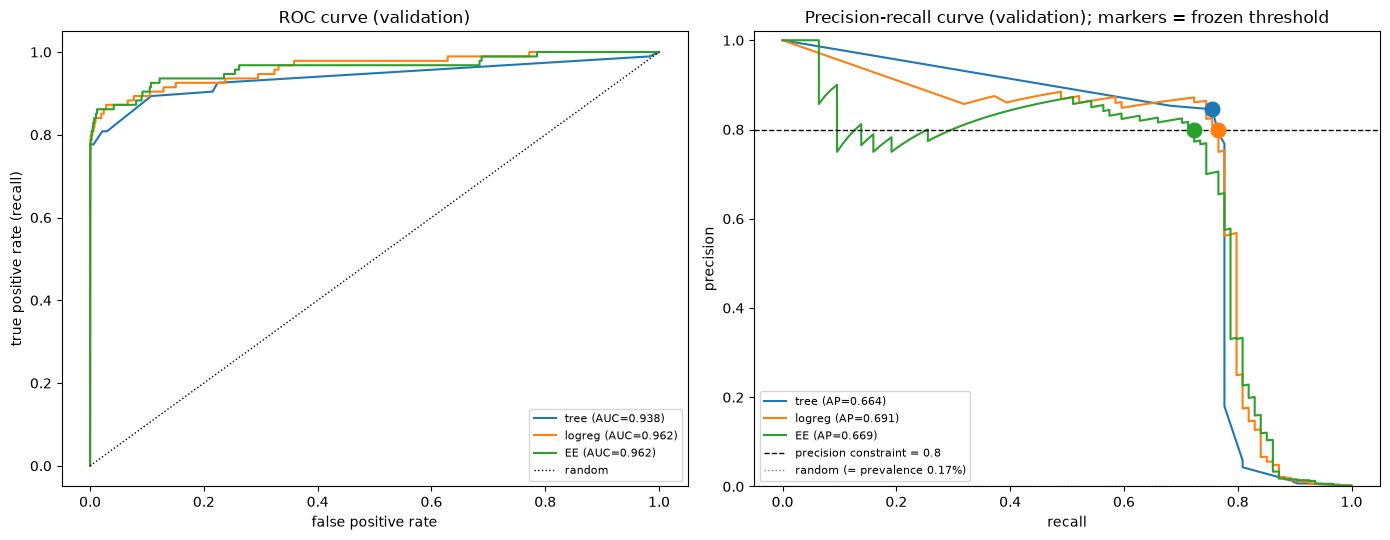

In [37]:
sup_cfg, sup_scores, sup_op = utils.collect_detectors([best_sup, best_ee], {**sup, **ee})   # tree, logistic regression, EasyEnsemble
utils.plot_pr_roc(sup_scores, cc['yva'], MIN_PRECISION_FRAUD, sup_op); plt.show()

**Comparison of the three supervised models (validation).** Their precision-recall curves are very close. EasyEnsemble has the same AUC as logistic regression (0.962) but a slightly lower recall (0.723 vs 0.766, and 0.755 for the tree, i.e. 3-4 frauds apart, not significant). **The method selected in Part 2 remains logistic regression**; EasyEnsemble is evaluated on the test set as the Part 3 method, without changing that selection.

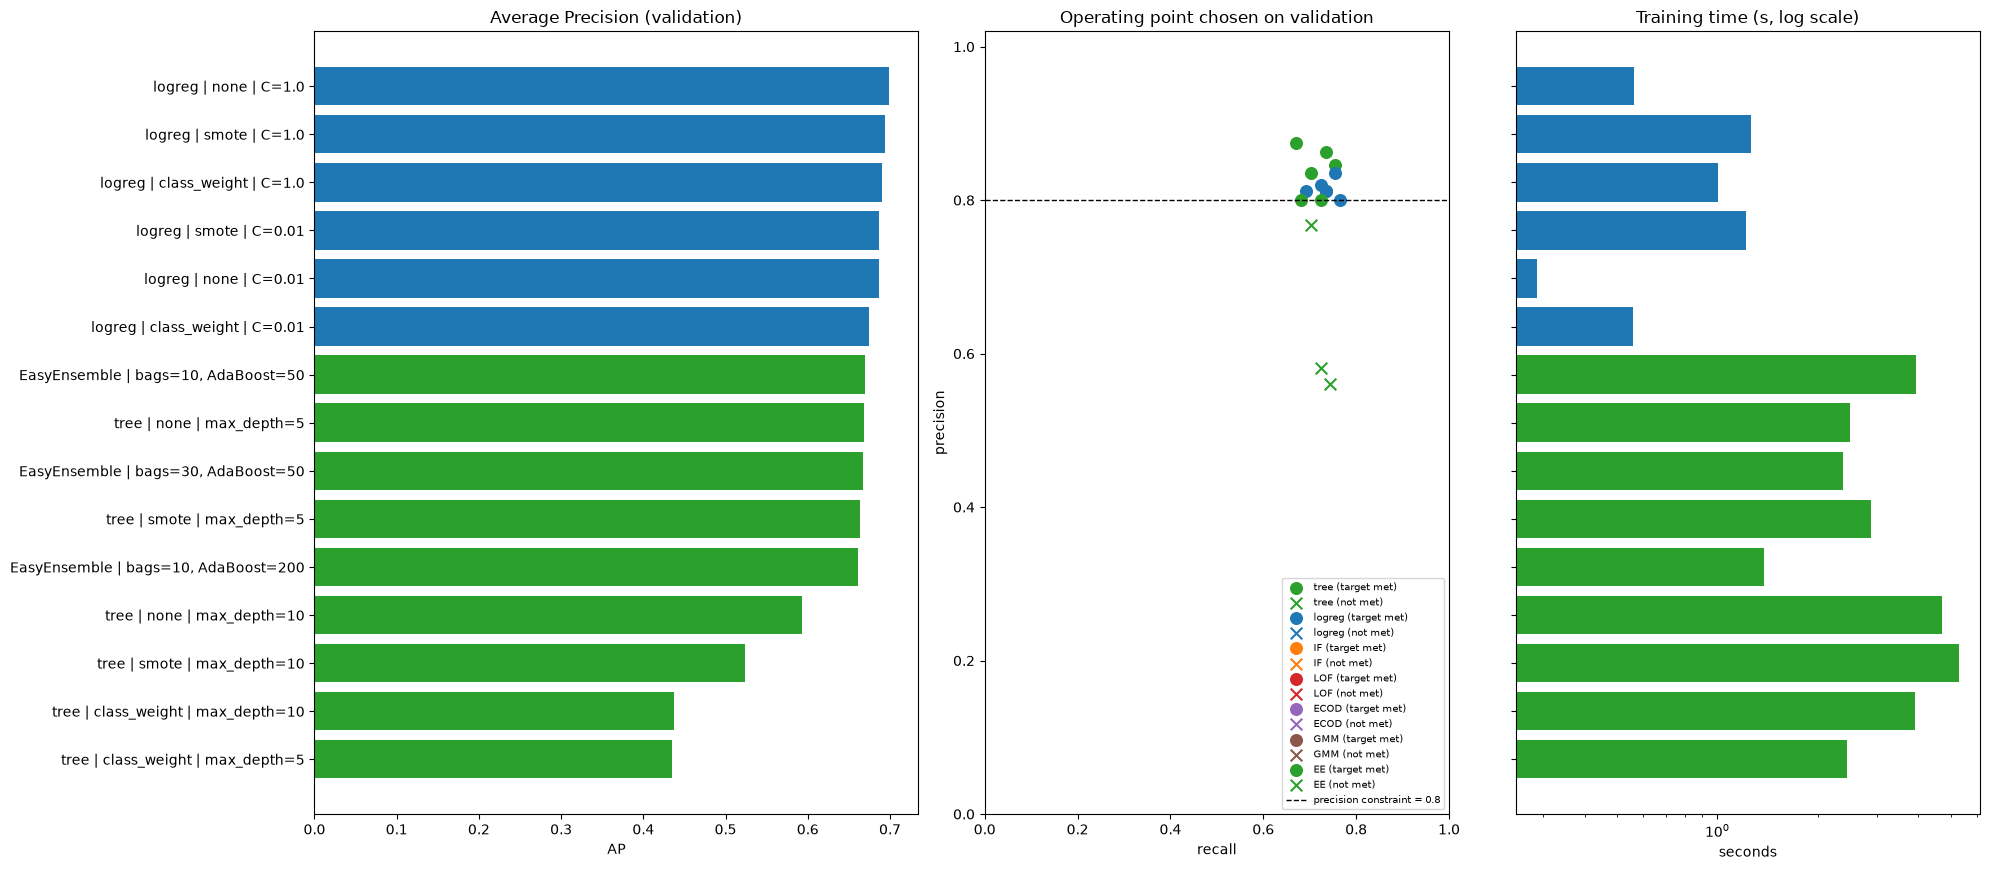

In [38]:
utils.plot_config_overview(pd.concat([res_sup, res_ee])); plt.show()

#### Test-set evaluation (once, frozen model and threshold)

In [39]:
test_res3, table3 = utils.evaluate_part3_on_test(ee, best_ee['EE'], test_res, rows_p3, cc, MIN_PRECISION_FRAUD)

,val AP,test AP,val AUC,test AUC,val precision,test precision,val recall,test recall,test F1,test alerts,test FP,test FN,fit time (s),test scoring (s),constraint ≥ 0.8 (test)
method,,,,,,,,,,,,,,,
EasyEnsemble,0.669,0.717,0.962,0.975,0.800,0.768,0.723,0.768,0.768,95,22,22,3.937,0.502,False
Isolation Forest,0.136,0.237,0.945,0.955,0.190,0.201,0.426,0.442,0.276,209,167,53,0.410,0.193,False
LOF,0.337,0.403,0.950,0.956,0.434,0.463,0.660,0.663,0.545,136,73,32,1.074,2.023,False


**Result – test set.**
- **EasyEnsemble**: 95 alerts, **73 frauds and 22 false alarms**, 22 frauds missed out of 95: precision **0.768 → constraint not met** (the threshold is not changed). IF and LOF: not met either.
- **Why**: (1) the threshold was chosen where validation precision just crosses 0.8 (68/85), an optimistic value by construction; (2) the 95 % CI of test precision, **[0.67, 0.84]**, contains 0.8: the gap is not significant; (3) at a fixed threshold, the test set gives 10 more alerts (5 true, 5 false).
- Logistic regression, also retained at exactly 0.800 on validation, got 0.882: the three supervised models are statistically close and the **draw** decides between them.
- **The ranking generalises**: AP 0.717 and AUC 0.975 on test (0.669 and 0.962 on validation), order EasyEnsemble > LOF > IF preserved. Only the exact threshold is fragile.

#### Test-set plots: EasyEnsemble, IF and LOF

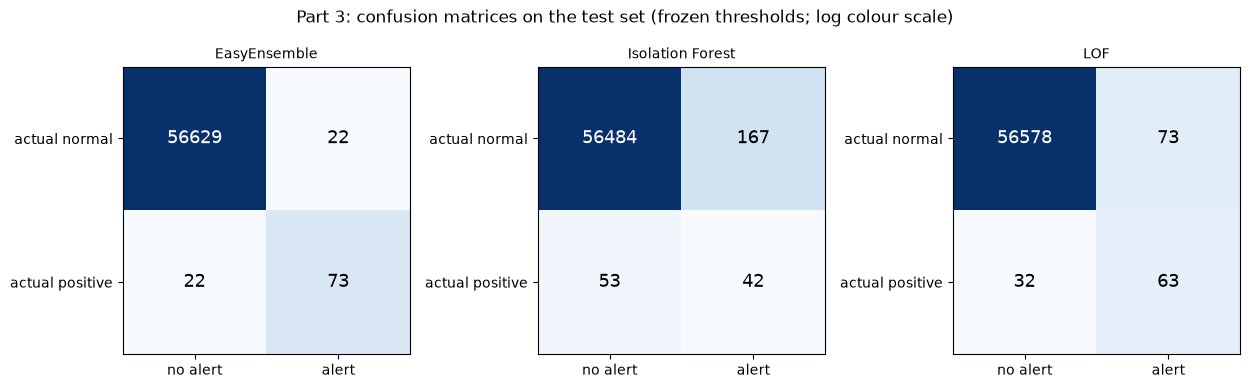

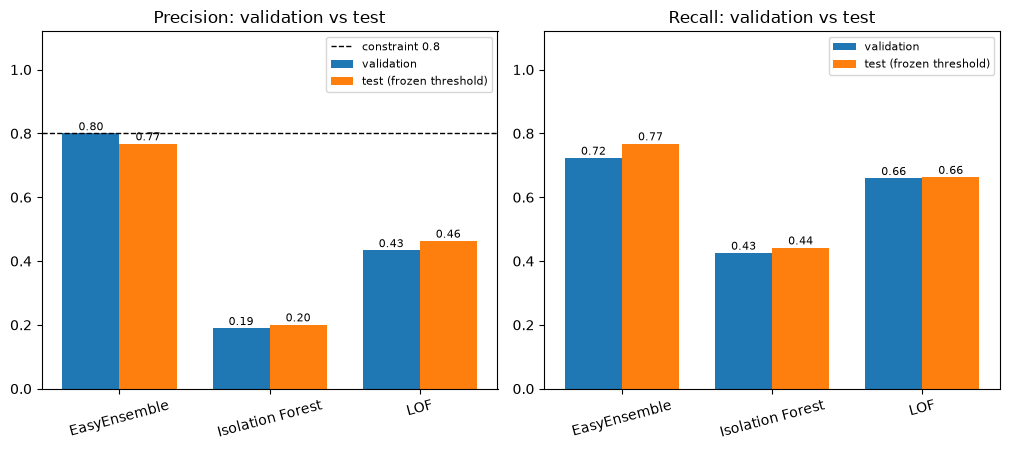

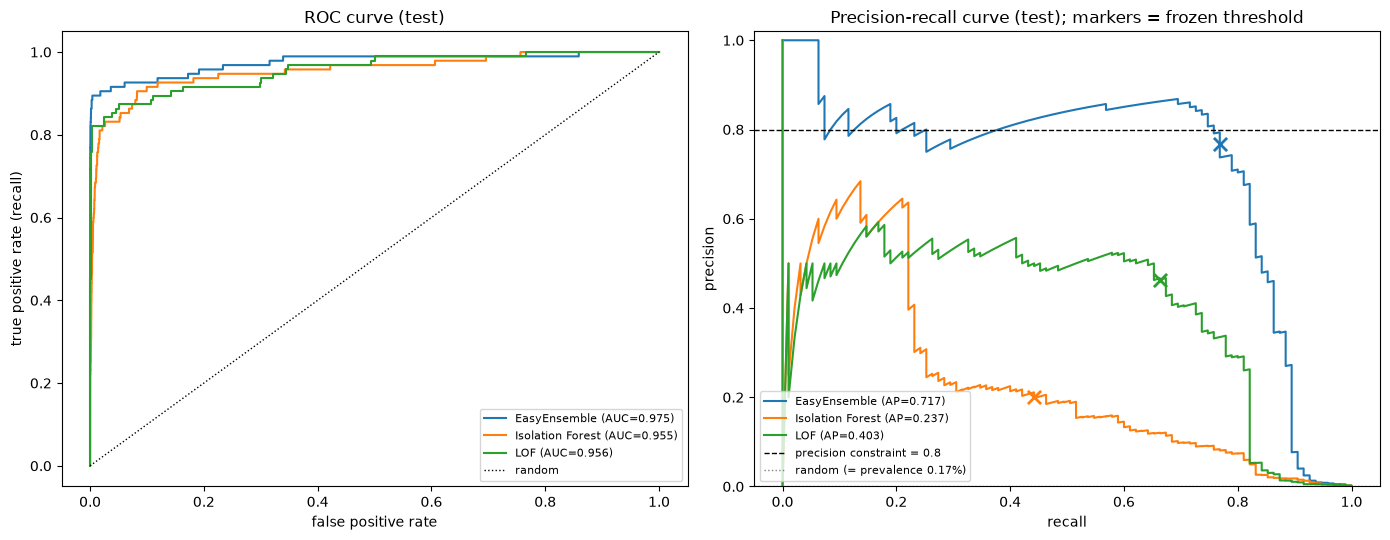

{'EasyEnsemble': {'precision': 0.7684210526315789,
  'recall': 0.7684210526315789,
  'feasible': False},
 'Isolation Forest': {'precision': 0.20095693779904306,
  'recall': 0.4421052631578947,
  'feasible': False},
 'LOF': {'precision': 0.4632352941176471,
  'recall': 0.6631578947368421,
  'feasible': False}}

In [40]:
utils.report_test_graphs(test_res3, rows_p3, cc['yte'], MIN_PRECISION_FRAUD, subject='Part 3')

**Reading.** EasyEnsemble has 3 to 8 times fewer false alarms than the detectors and misses fewer frauds. Its precision goes from 0.80 (validation) to 0.77 (test), while IF and LOF stay stable and very low. On the test precision-recall curve, the frozen threshold falls just after the point where the curve leaves the 0.8 line: the constraint is narrowly missed.

### Part 3 summary
- **Success**: the only one of the three methods to meet the constraint on validation, with an AP 2 to 5 times that of LOF and IF (0.669 vs 0.337 and 0.136; on test 0.717 vs 0.403 and 0.237). Thanks to the labels, it learns to place frauds in a score range where normal rows are rare.
- **Limitations**: it needs **reliable labels** (unusable without known frauds, blind to new fraud patterns); uncalibrated probabilities (0.5 threshold unusable); threshold retained at the edge of the constraint, hence the test failure despite a good ranking; no better than logistic regression.
- **Cost**: training around 1-2 s (each AdaBoost only sees ≈ 568 rows); scoring comparable to LOF, growing with *T* × stumps.

---
<a id="part3bis"></a>

## Part 3bis. Unsupervised complement: ECOD and GMM (validation only)
To position an **unsupervised** method beyond the course relative to IF and LOF:
- **ECOD**: Z. Li *et al.*, *ECOD: Unsupervised Outlier Detection Using Empirical Cumulative Distribution Functions*, IEEE TKDE, 2022. Implemented from scratch (`ECODDetector`, `numpy`).
- **GMM** (Gaussian mixture, `sklearn.mixture.GaussianMixture`), score = −log-likelihood.

**ECOD principle.** For each feature, the empirical CDF of the training set gives the probability of being as extreme (left or right tail). Assuming **independent** features, the score is the sum of the −log of these probabilities: an observation that is extreme on many features is suspicious. Three ways to combine tails (our 3 configurations): `auto` (by skewness), `both` (max of left and right sums), `max` (max of the three sums, the paper's version).

**Assumptions and limits**: anomalies = extreme values on at least one feature; an unusual combination of ordinary values is invisible to it. **Why here**: V1..V28 are decorrelated (PCA) and heavy-tailed; ECOD is fast, needs no scaling, and its score decomposes per feature. GMM: 3 configurations ((3, full), (8, full), (8, diag)).

In [41]:
new, res_new = utils.run_new_methods(cc, MIN_PRECISION_FRAUD, prep_scaled=prep_scaled)

,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,F1@default,alerts@default,t_fit (s),t_score (s)
config,,,,,,,,,,,,,,
ECOD | tail=auto,0.221,0.918,72.558,0.297,0.468,148,False,0.364,104,50,0.027,5663,1.259,0.374
ECOD | tail=both,0.249,0.928,74.837,0.353,0.383,102,False,0.367,66,58,0.028,5723,1.268,0.375
ECOD | tail=max,0.207,0.925,76.838,0.292,0.447,144,False,0.353,102,52,0.027,5686,1.286,0.379
"GMM | n_components=3, covariance=full",0.109,0.923,146.976,0.182,0.330,170,False,0.235,139,63,0.027,5776,7.219,0.036
"GMM | n_components=8, covariance=full",0.087,0.933,108.001,0.242,0.160,62,False,0.192,47,79,0.028,5830,17.996,0.083
"GMM | n_components=8, covariance=diag",0.188,0.953,81.737,0.233,0.436,176,False,0.304,135,53,0.028,5720,4.781,0.028


**Result (validation).**
- **Target not met** by any of the 6 configurations.
- **ECOD**: the three variants are close (AP 0.21 to 0.25); `both` is the best.
- **GMM**: diagonal covariance (the simplest) is the best (AP 0.188); full covariances do worse (hypothesis: they also "explain" atypical transactions).
- Default thresholds (prior contamination of 10 %) unusable: ≈ 5,700 alerts.
- **Time**: ECOD ≈ 1 s; GMM from a few seconds to more than 10 s.

In [42]:
best_new = utils.best_per_family(res_new, ['ECOD', 'GMM'], pool=new, y_val=cc['yva'])
det_cfg, det_pool, det_scores, det_op = utils.collect_best_detectors(best_unsup, best_new, unsup, new)
for lab, cfg in det_cfg.items(): print(f'{lab:17s} -> {cfg}')

,config,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,FP,FN
ECOD,ECOD | tail=both,0.249011,0.928419,74.837232,0.352941,0.382979,102,False,66,58
GMM,"GMM | n_components=8, covariance=diag",0.188378,0.953415,81.736726,0.232955,0.43617,176,False,135,53


ECOD (ECOD | tail=both): max precision with >= 10 alerts = 0.600 (recall 0.096, 15 alerts)
GMM (GMM | n_components=8, covariance=diag): max precision with >= 10 alerts = 0.476 (recall 0.106, 21 alerts)
Isolation Forest  -> IF | n_estimators=100, max_samples=4096
LOF               -> LOF | n_neighbors=100
ECOD              -> ECOD | tail=both
GMM               -> GMM | n_components=8, covariance=diag


**Result.** Ranking by AP: **LOF (0.337) > ECOD (0.249) > GMM (0.188) > IF (0.136)**. ECOD has the **best precision at the top of the ranking** (0.60 with 15 alerts, vs 0.50 for LOF).

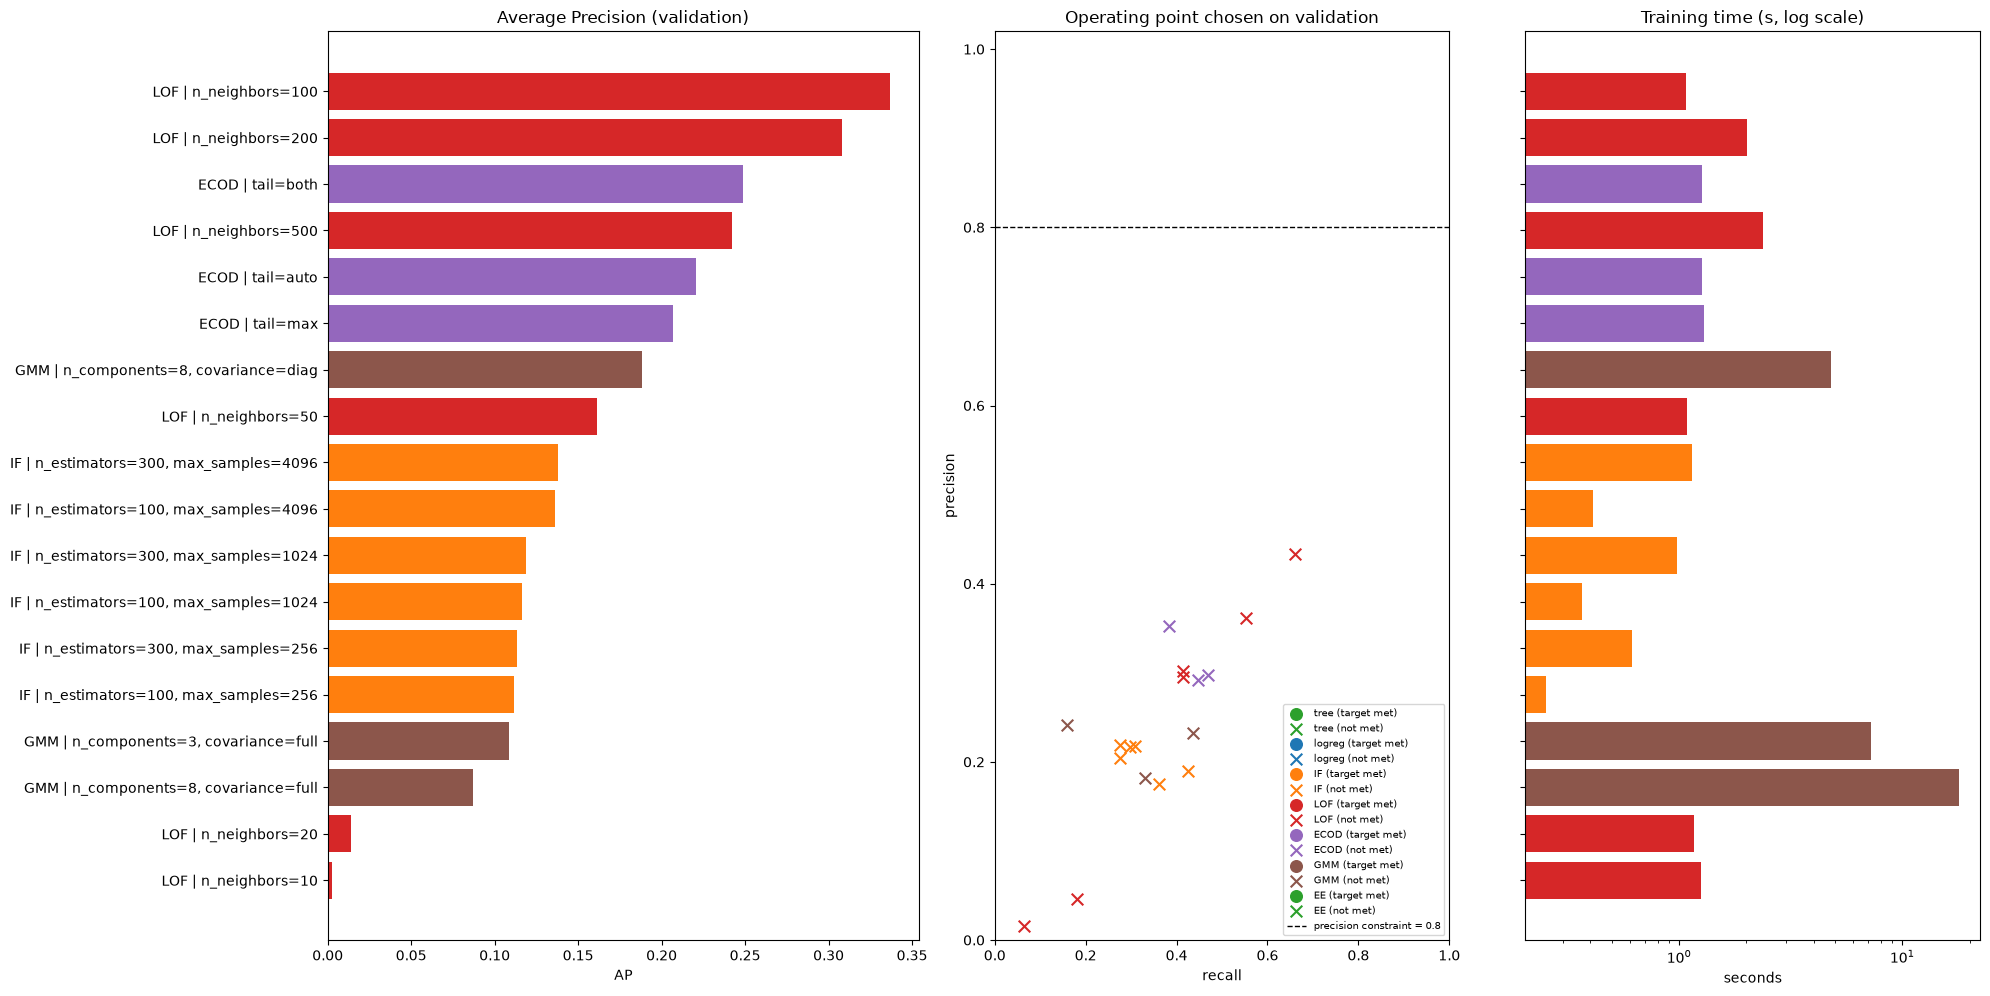

In [43]:
utils.plot_config_overview(pd.concat([res_unsup, res_new])); plt.show()

**Reading.** ECOD configurations (purple) sit above all IF and GMM configurations, below LOF k = 50 to 200; all remain far from 0.8 precision. ECOD is the cheapest of the detectors with a good AP.

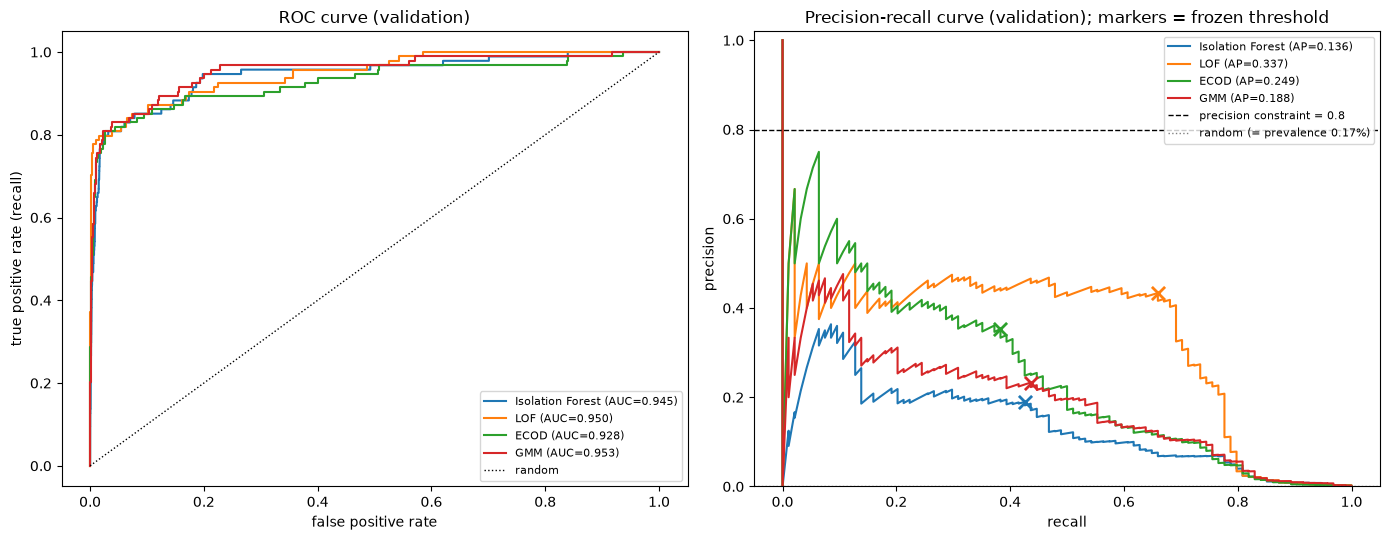

In [44]:
utils.plot_pr_roc(det_scores, cc['yva'], MIN_PRECISION_FRAUD, det_op); plt.show()

**Reading.** On ROC, the four detectors are grouped (AUC 0.928 to 0.953; ECOD lowest). On precision-recall, ECOD is the best on the very first alerts (≈ 0.75 precision at a recall of 0.06), then LOF clearly overtakes it. No curve reaches 0.8 beyond a near-zero recall.

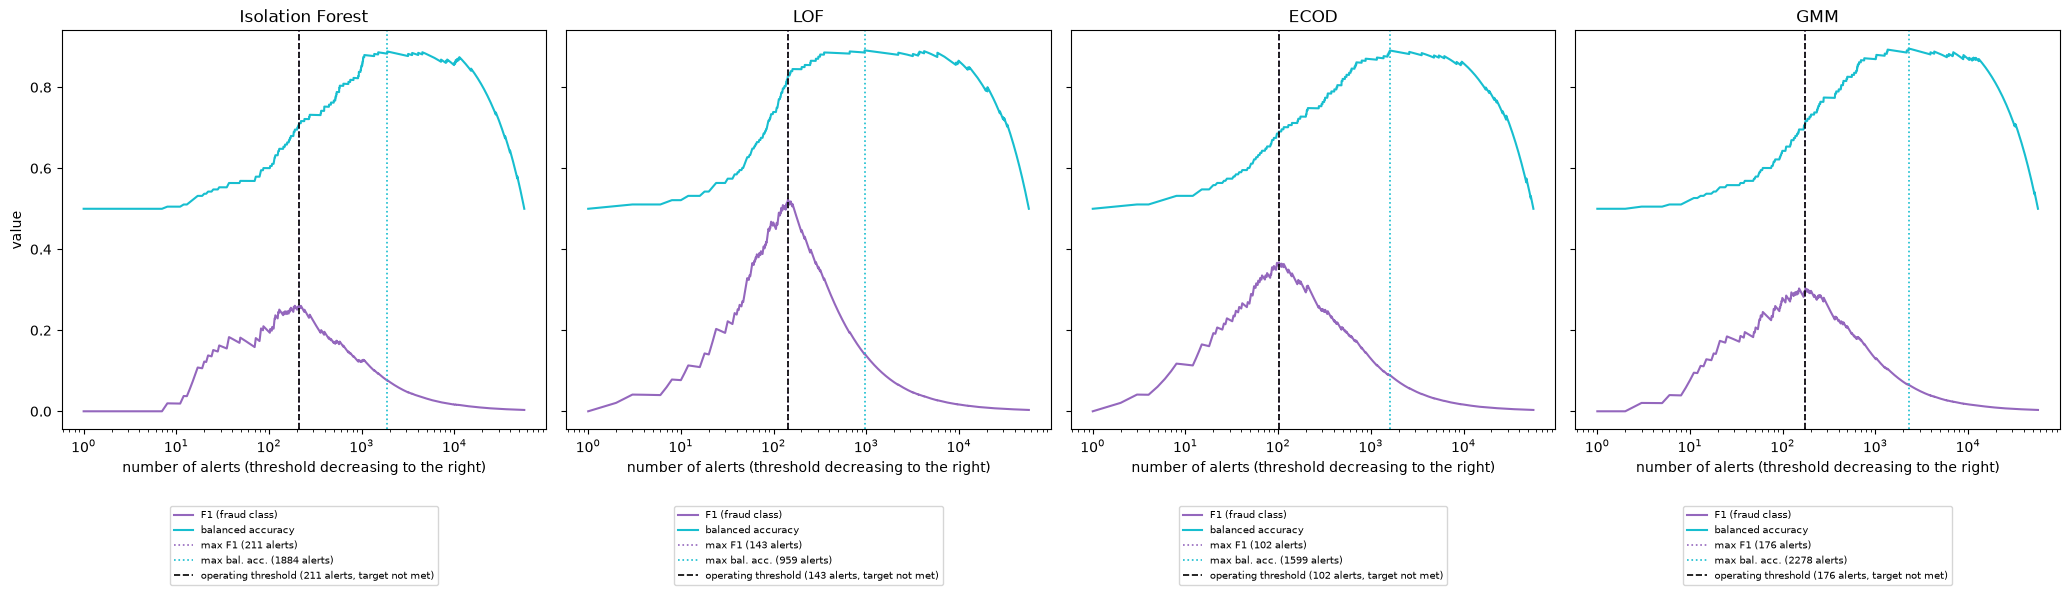

In [45]:
utils.plot_threshold_sweep(det_scores, cc['yva'], det_op); plt.show()

**Reading.** Max F1 at 102 alerts for ECOD (0.37), 143 for LOF (0.52), 176 for GMM, 211 for IF; balanced accuracy peaks between 959 and 2,278 alerts, unrelated to the precision constraint.

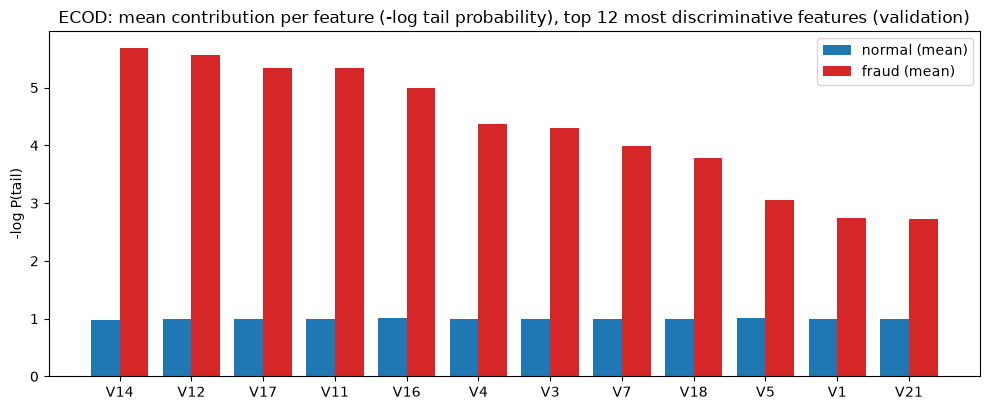

In [46]:
ecod_best = det_pool[det_cfg['ECOD']]['model']
utils.plot_ecod_contributions(ecod_best, cc['Xva'], cc['yva']); plt.show()

**ECOD: success, limit and cost.**
- **Success**: best precision at the top of the ranking and AP 1.8 times that of IF, with no tuning. The figure decomposes the score: for normal rows, each feature contributes ≈ **1.0** (theoretical value of E[−log P] for uniform P, which validates the implementation); for frauds, **V14, V12, V17, V11, V16** rise to 5-5.7. These are properties of the model, not business explanations (anonymised features).
- **Limit**: it only sees extremes **feature by feature**; a fraud made of ordinary values combined in an unusual way escapes it, whereas LOF (density in 29 dimensions) can catch it.
- **Cost**: training ≈ 1 s, fast scoring, no neighbours or iterations.

These methods are **not evaluated on the test set**: the official Part 3 method is EasyEnsemble.

---
<a id="part4"></a>

# Part 4 – Transfer to predictive maintenance (AI4I 2020)
**a) Data.** Target: `Machine failure`. Inputs: `Type` (L/M/H) and 5 numeric features (temperatures, speed, torque, tool wear). We **drop** `UDI`, `Product ID` and `TWF`, `HDF`, `PWF`, `OSF`, `RNF`: the latter describe the failure type and would leak the target.

**b) Preprocessing** (fitted on train): one-hot for `Type`, `StandardScaler` for numeric features (logistic regression); one-hot only for IF. The data is **synthetic**: conclusions do not transfer as is to a real plant.

**c) Methods**: Isolation Forest (100 trees, `max_samples` = 4096) and the best supervised model from Credit Card (weighted logistic regression, C = 1). **Same hyperparameters, but models and transformations are refitted**; thresholds are not reused.

**d) Objective**: 60/20/20 split, threshold chosen on validation to **maximise recall subject to precision ≥ 90 %**, test set used once.

### 1. Data inspection

In [47]:
df_ai = utils.ai4i_overview(utils.DATA_DIR / 'ai4i2020.csv')

shape: (10000, 14) | missing values: 0 | duplicated rows: 0
failures (Machine failure = 1): 339 / 10000 = 3.39%


,n,failures,rate
Type,,,
H,1003,21,0.0209
L,6000,235,0.0392
M,2997,83,0.0277


failure types (descriptive, not used): {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19} | failures without type: 9


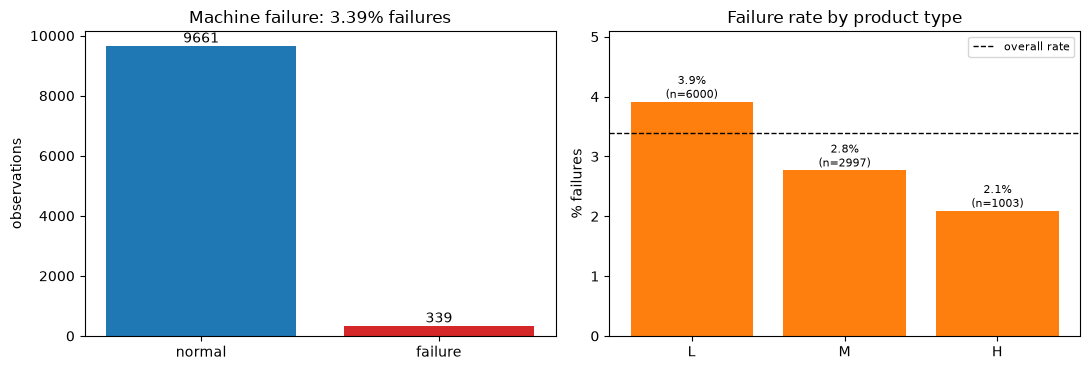

In [48]:
utils.plot_ai4i_frequency(df_ai); plt.show()

**Result.** **339 failures (3.39 %)**, a prevalence 20 times higher than fraud. No missing values or duplicates. The rate varies by type (L 3.9 %, M 2.8 %, H 2.1 %), and several failure mechanisms are mixed in the target (HDF 115, OSF 98, PWF 95, TWF 46, RNF 19).

### 2. Stratified 60 / 20 / 20 split

In [49]:
ai = utils.ai4i_split(df_ai)

,observations,failures,rate
train,6000.0,203.0,0.033833
validation,2000.0,68.0,0.034000
test,2000.0,68.0,0.034000


**Result.** 6,000 / 2,000 / 2,000 observations (203 / 68 / 68 failures). One failure = 1.5 % of recall. No identifier or failure-type column in `X` (checked with `assert`).

### 3. Fitting, threshold choice on validation

In [50]:
MIN_PRECISION_MAINT = utils.MIN_PRECISION_MAINTENANCE   # constraint: precision >= 90 %
res_ai, rows_ai, cfg_ai = utils.run_ai4i_methods(ai, MIN_PRECISION_MAINT)
scores_ai = {k: res_ai[k]['scores_val'] for k in rows_ai}

,AP,AUC-ROC,threshold,precision,recall,n_alerts,feasible,F1,FP,FN,alerts@default,precision@default,t_fit (s),t_score (s)
Logistic regression,0.407168,0.881051,0.979916,0.916667,0.161765,12,True,0.275,1,57,358,0.150838,0.010964,0.00296
Isolation Forest,0.151227,0.79118,0.666981,1.0,0.029412,2,True,0.057143,0,66,350,0.1,0.172971,0.016194


**Result (validation, precision ≥ 90 %).**
- **Target met, but on very few alerts**: 12 for logistic regression (11 failures prevented, 1 unnecessary; recall 0.16), **only 2** for IF (recall 0.03). One more false alarm would push logistic regression below 0.9.
- At the 0.5 threshold, logistic regression raises 358 alerts (precision 15 %). At max F1, 93 alerts for a precision of 0.37 and a recall of 0.50: the 90 % constraint is very costly in recall.
- Thresholds differ from Credit Card (0.980 vs 0.999994): different scales and prevalences.

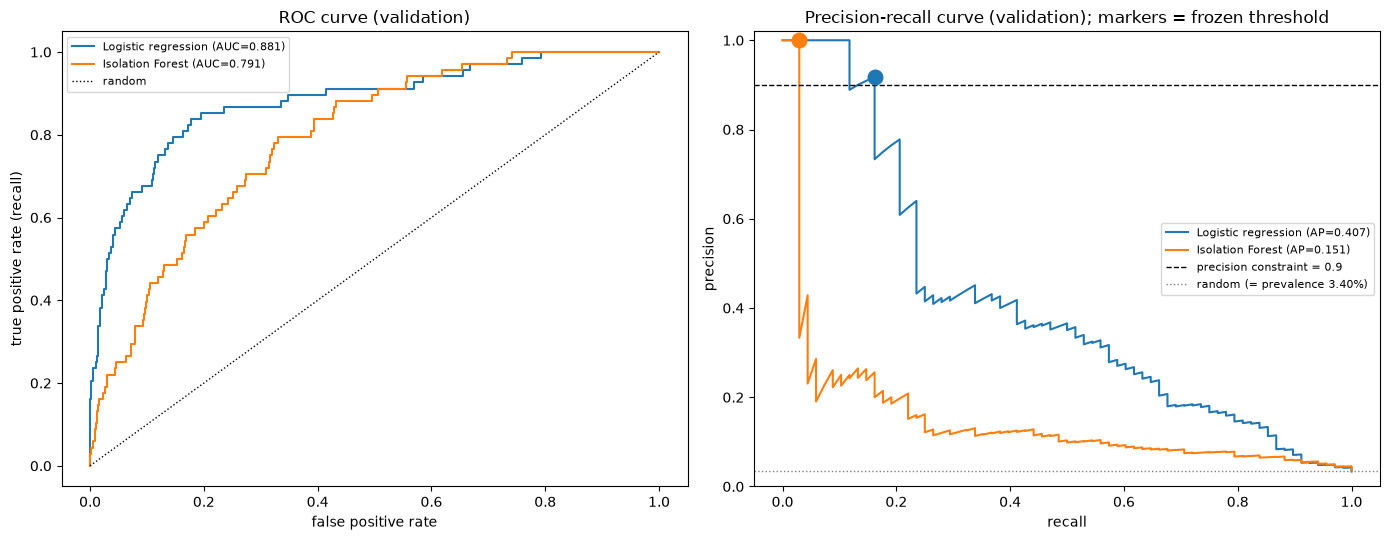

In [51]:
utils.plot_pr_roc(scores_ai, ai['yva'], MIN_PRECISION_MAINT, rows_ai); plt.show()

**Reading.** Logistic regression (AUC 0.881) dominates IF (0.791). On precision-recall, its precision is 1 up to a recall of ≈ 0.12, then drops; the retained point is at the edge of this drop. The APs (0.41 and 0.15) should be compared with random, here 3.4 %.

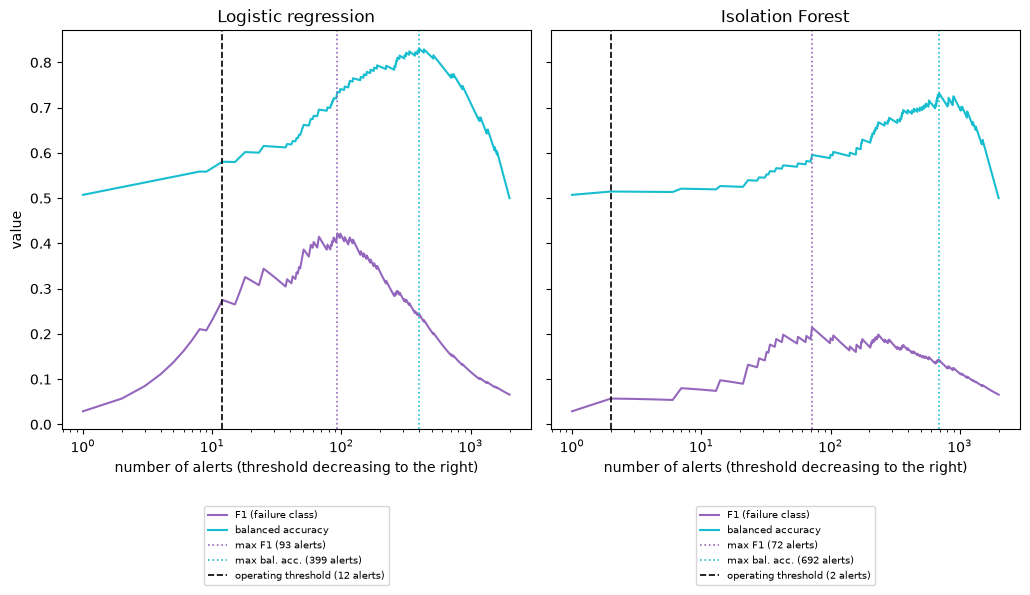

In [52]:
utils.plot_threshold_sweep(scores_ai, ai['yva'], rows_ai, pos='failure'); plt.show()

**Reading.** Max F1 at 93 alerts (logistic regression) and 72 (IF); max balanced accuracy at 399 and 692 alerts. The operating threshold (12 and 2 alerts) is much stricter: requiring 9 correct alerts out of 10 has nothing to do with these criteria.

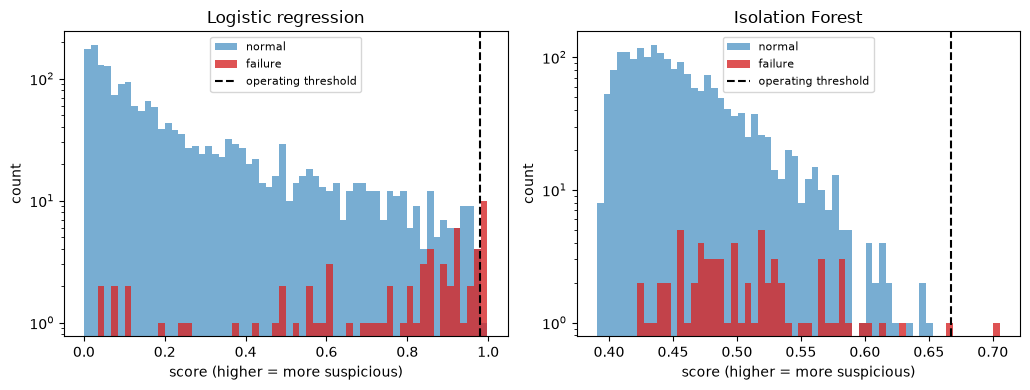

In [53]:
utils.plot_score_hist(scores_ai, ai['yva'], rows_ai, pos='failure'); plt.show()

**Reading.** For logistic regression, only the top of the distribution is "clean": many failures are spread over the whole range, mixed with normal rows. For IF, failures are mixed with normal rows everywhere.

,default threshold,alerts (default),precision (default),recall (default),F1 (default),retained threshold,alerts (retained),precision (retained),recall (retained),F1 (retained),target met
Logistic regression,0.5,358,0.150838,0.794118,0.253521,0.979916,12,0.916667,0.161765,0.275,True
Isolation Forest,0.5,350,0.1,0.514706,0.167464,0.666981,2,1.0,0.029412,0.057143,True


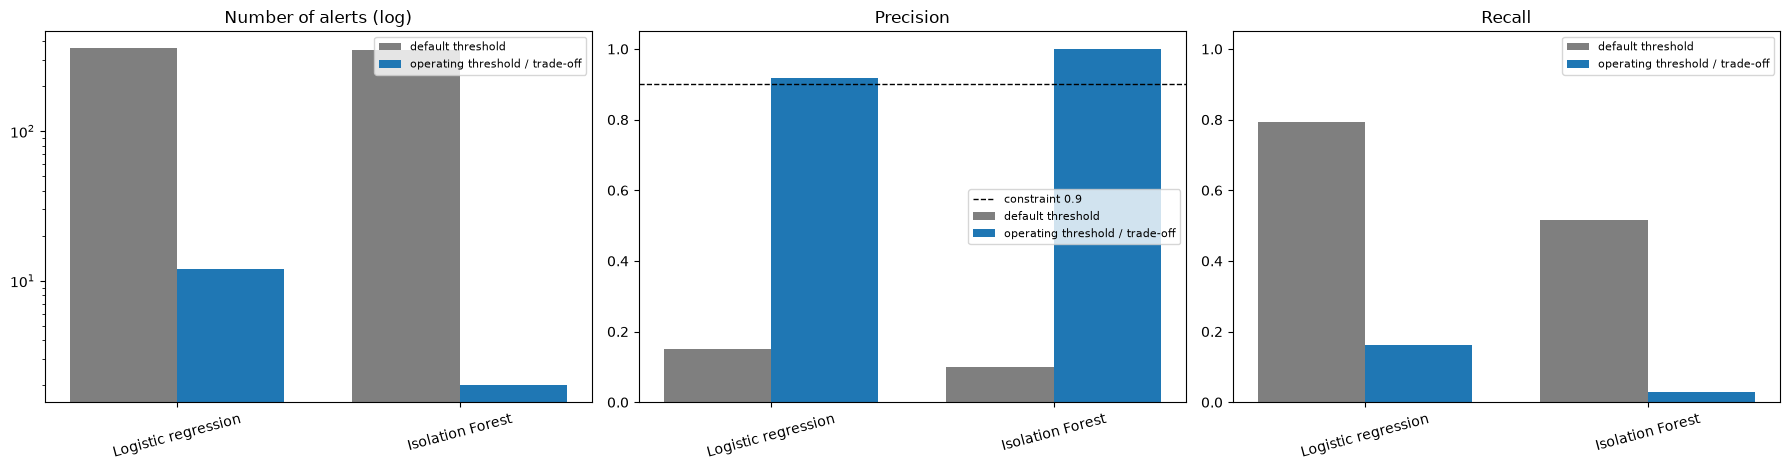

In [54]:
utils.report_default_vs_operational(rows_ai, MIN_PRECISION_MAINT); plt.show()

**Result.** The retained threshold divides the number of interventions by 30 (logistic regression: 358 → 12) to 175 (IF: 350 → 2).

### 4. Selection on validation, then test-set evaluation (once)

In [55]:
SEL_AI, FROZEN_AI = utils.select_and_freeze(rows_ai, cfg_ai)

Method selected on validation: Logistic regression  (logreg | class_weight | C=1.0)
  frozen threshold = 0.979916 | validation: precision 0.917, recall 0.162, 12 alerts, target met = True


,config,threshold
Logistic regression,logreg | class_weight | C=1.0,0.979916
Isolation Forest,"IF | n_estimators=100, max_samples=4096",0.666981


**Selection (validation, before the test): logistic regression** (recall 0.162 vs 0.029 for IF). Model and threshold (0.979916) are frozen.

In [56]:
test_ai, final_ai = utils.evaluate_ai4i_on_test(ai, res_ai, FROZEN_AI, SEL_AI, rows_ai, MIN_PRECISION_MAINT)

,preprocessing,tuning,AP,AUC-ROC,frozen threshold,precision,recall,F1,bal. acc.,interventions,unnecessary interventions (FP),missed failures (FN),fit time (s),test scoring time (s),constraint ≥ 0.9 met on test
method,,,,,,,,,,,,,,,
★ Logistic regression,one-hot(Type) + StandardScaler (fitted on train),"class weighting, C=1 (Credit Card hyperparamet...",0.409,0.905,0.980,1.000,0.059,0.111,0.529,4,0,64,0.011,0.003,True
Isolation Forest,"one-hot(Type), raw numeric features","100 trees, max_samples=4096 (Credit Card hyper...",0.114,0.765,0.667,0.667,0.029,0.056,0.514,3,1,66,0.173,0.016,False


**Result – test set (2,000 observations, 68 failures).**

| Method | AP | AUC | Precision | Recall | Interventions | Unnecessary | Missed failures | ≥ 0.9 |
|---|---|---|---|---|---|---|---|---|
| ★ **Logistic regression** | 0.409 | 0.905 | **1.000** | 0.059 | 4 | 0 | 64 | met |
| Isolation Forest | 0.114 | 0.765 | 0.667 | 0.029 | 3 | 1 | 66 | no |

- **4 interventions, all useful, but 64 failures out of 68 missed.** The constraint is met on only 4 alerts: 95 % CI of precision [0.51, 1.0], so nothing is guaranteed.
- APs are close to validation and the order is preserved: the ranking generalises, but the 90 % constraint only allows handling 6 % of the failures. To catch half of them, ≈ 93 interventions would be needed (precision ≈ 0.37 on validation).

#### Test-set plots (AI4I)

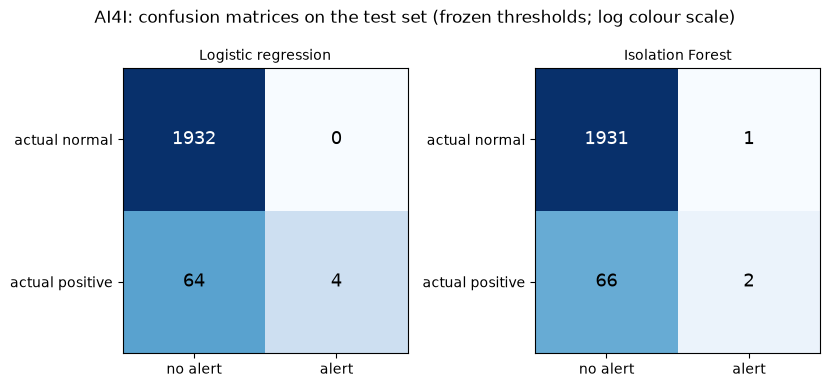

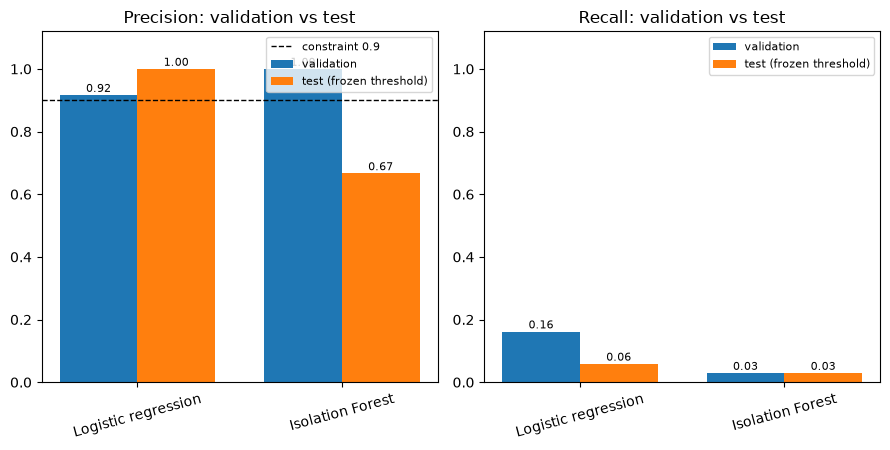

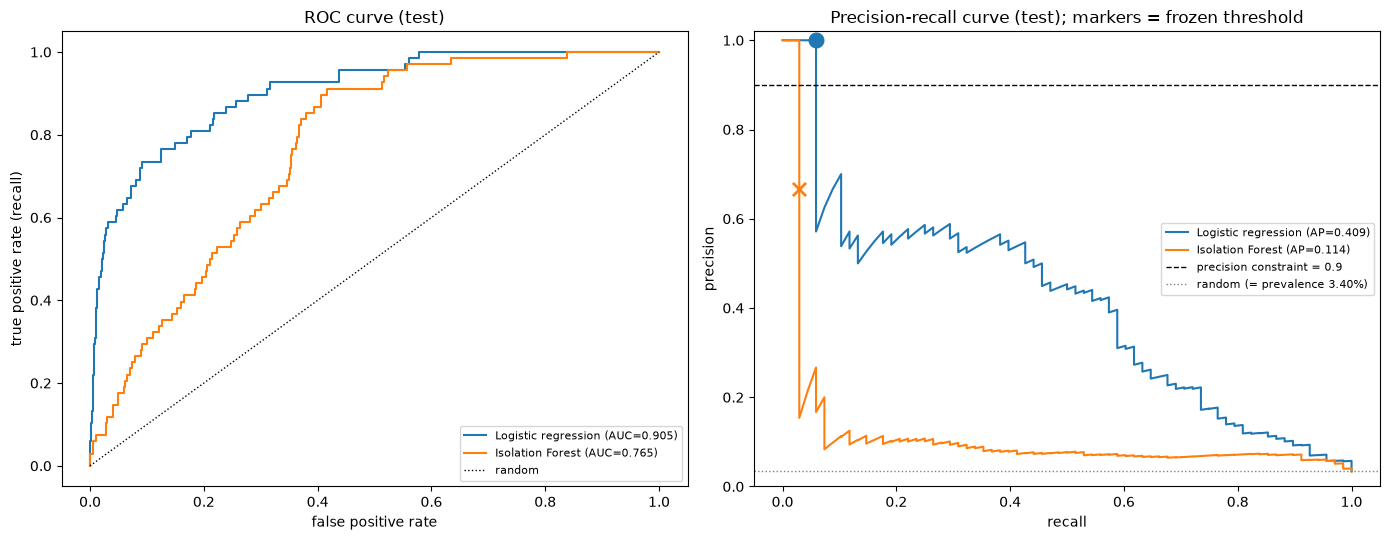

{'Logistic regression': {'precision': 1.0,
  'recall': 0.058823529411764705,
  'feasible': True},
 'Isolation Forest': {'precision': 0.6666666666666666,
  'recall': 0.029411764705882353,
  'feasible': False}}

In [57]:
utils.report_test_graphs(test_ai, rows_ai, ai['yte'], MIN_PRECISION_MAINT, subject='AI4I')

**Reading.** 94 % (logistic regression) and 97 % (IF) of failures go undetected. Precisions rest on 2 to 12 alerts and are therefore unreliable. On the test curve, logistic regression precision is 1 for the very first alerts, then drops to 0.6-0.7: only a handful of alerts satisfy the constraint.

In [58]:
utils.report_selected_on_test(test_ai, SEL_AI, FROZEN_AI, rows_ai, MIN_PRECISION_MAINT, unit='failure')

Test: 2000 observations incl. 68 positives (3.400%) | method: Logistic regression, frozen threshold 0.979916
- interventions triggered: 4 (0.200% of observations) incl. 4 failures prevented and 0 unnecessary interventions
- detected: 4 / 68; missed failures: 64
- precision 1.000 (95 % Wilson CI: 0.510 - 1.000); recall 0.059 (95 % CI: 0.023 - 0.142)
- precision constraint >= 0.9 met on test: True | val -> test: precision 0.917 -> 1.000, recall 0.162 -> 0.059
- on average 1.00 alerts per failure prevented


In [59]:
thr_compare = utils.compare_thresholds_across_datasets(FROZEN, FROZEN_AI)

,Credit Card threshold,AI4I threshold
Logistic regression,0.999994,0.979916
Isolation Forest,0.578460,0.666981


#### AP relative to random (test set)
The AP of a random score equals the prevalence (0.17 % frauds, 3.4 % failures). Dividing AP by prevalence compares each method **with random on its own dataset**.

In [60]:
ap_prev = utils.ap_vs_prevalence(test_res, test_ai)

test AP  prevalence (random AP)  \
method              dataset                                        
Logistic regression Credit Card   0.7260                  0.0017   
                    AI4I          0.4087                  0.0340   
Isolation Forest    Credit Card   0.2371                  0.0017   
                    AI4I          0.1140                  0.0340   

                                 AP / prevalence  
method              dataset                       
Logistic regression Credit Card         433.6442  
                    AI4I                 12.0199  
Isolation Forest    Credit Card         141.5990  
                    AI4I                  3.3540

**Result.** Logistic regression: **434 ×** random on Credit Card vs **12 ×** on AI4I; IF: 142 × vs 3.4 ×. Raw APs (0.73 and 0.41) hide this gap: AI4I is genuinely harder for these methods, and IF is almost useless there.

### 5. Why the fraud winner may not be the best for failures
Logistic regression remains the better of the two, but its performance drops (AP 0.73 → 0.41, recall 0.79 → 0.06). Hypotheses (not tested):
- **Linear boundary vs heterogeneous failures**: failures combine several mechanisms (tool wear, heat dissipation, power, overstrain) that depend on **non-linear combinations** (torque × speed, temperature difference), poorly captured by a linear combination of the raw features.
- **20 times higher prevalence**: failures are no longer "few and different", IF's core assumption.
- **Few failures** (203 in training, 68 in validation) and synthetic data.

**Do not compare APs across datasets**: they do not share the same baseline (prevalence 3.4 % vs 0.17 %) and only serve to rank methods **within one dataset**. Likewise, thresholds do not transfer.

**Limitations**: constraint "met" on 4 alerts; only two methods (a non-linear model was not tried, as instructed); a single split.

---
<a id="part5"></a>

# Part 5 – Robustness and explainability
## 5.1 Contaminating the normal reference (Mouse)
**Protocol.**
- **Reference**: the 392 normal training points from Part 1.3. Training sets **of the same size** with **0 %, 5 % and 10 %** synthetic anomalies (0, 20 and 39 points) **replacing** normal points. The **real test set** from Part 1.3 (98 normal + 10 anomalies) is **unchanged**.
- **Two generators** (no labels; any point too close to the dense area is rejected): **`uniform`**, uniform draw in the bounding box enlarged by 20 %; **`local`**, a random normal point + Gaussian noise with std 0.1.
- **IF (100 trees) and LOF (k = 20, `novelty=True`)**, fixed hyperparameters, refitted each time; **3 seeds** (42, 43, 44). Metric: AP on the real test set (mean ± std).

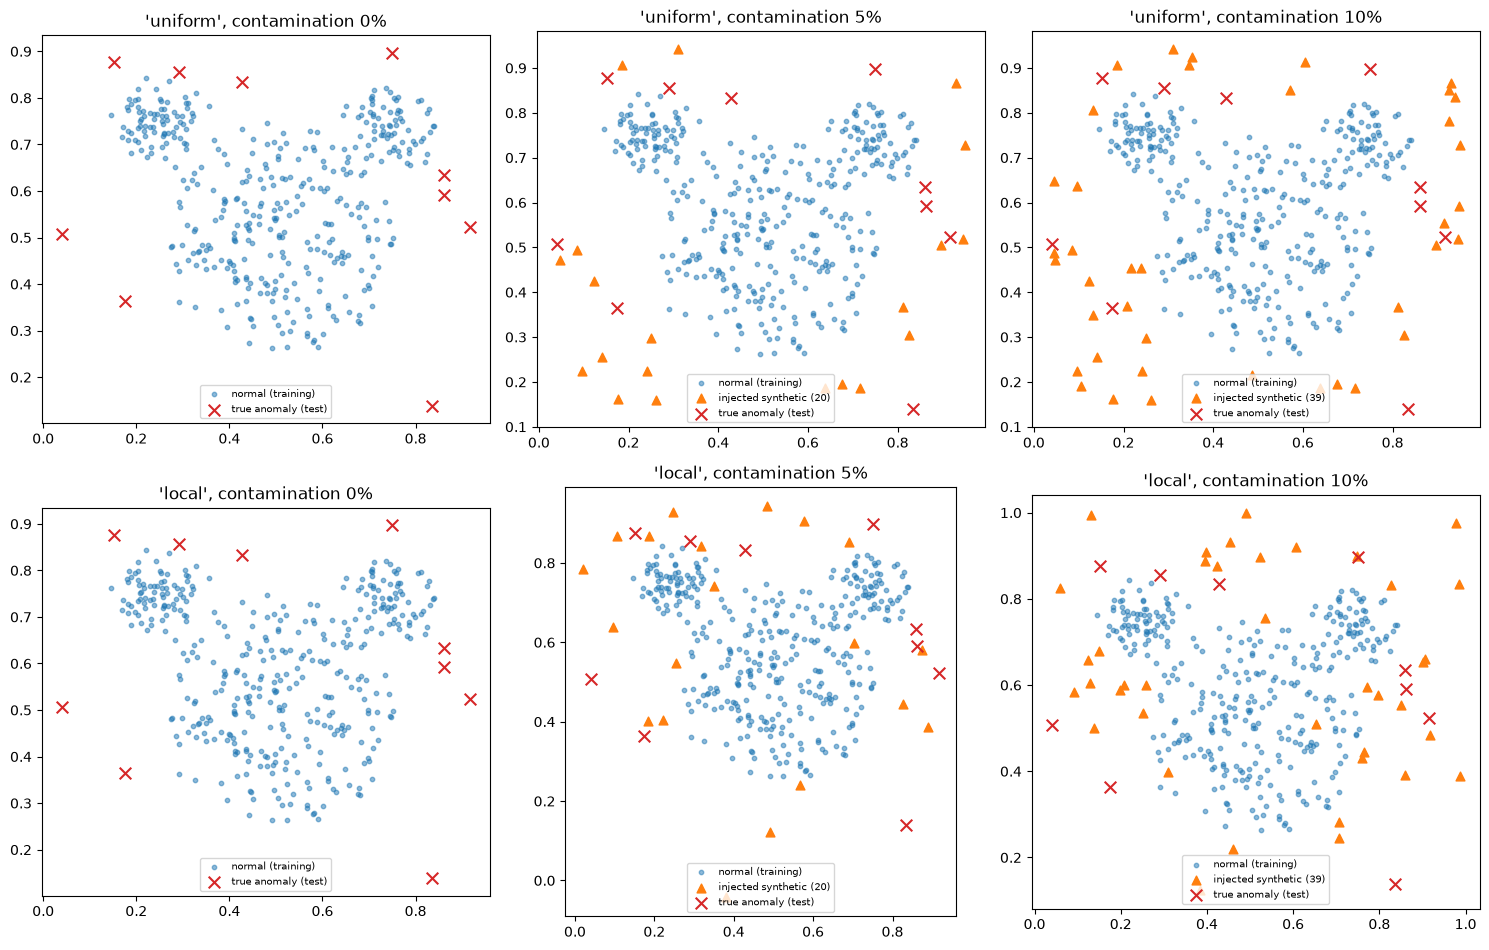

In [61]:
utils.plot_mouse_contamination_examples(X, y); plt.show()

**Reading (one seed; red crosses = true anomalies, orange triangles = injected anomalies).** With `uniform`, injected points surround the shape, **in the same area as the true anomalies**; with `local`, they are closer to the shape, sometimes inside the ears or the face.

In [62]:
rob = utils.mouse_robustness(X, y)

mean    std    min    max
generator method           contamination                            
local     Isolation Forest 0.00           0.756  0.008  0.747  0.763
                           0.05           0.893  0.039  0.848  0.919
                           0.10           0.852  0.038  0.821  0.894
          LOF (k=20)       0.00           1.000  0.000  1.000  1.000
                           0.05           0.994  0.010  0.983  1.000
                           0.10           0.964  0.014  0.948  0.977
uniform   Isolation Forest 0.00           0.756  0.008  0.747  0.763
                           0.05           0.900  0.058  0.852  0.965
                           0.10           0.936  0.032  0.903  0.967
          LOF (k=20)       0.00           1.000  0.000  1.000  1.000
                           0.05           0.997  0.005  0.991  1.000
                           0.10           0.986  0.025  0.957  1.000

**Result (AP on the real test set).** LOF: 1.00 → 0.986 (`uniform`) or 0.964 (`local`) at 10 %. IF: 0.756 → 0.936 (`uniform`) or 0.852 (`local`). At 0 %, both generators coincide.

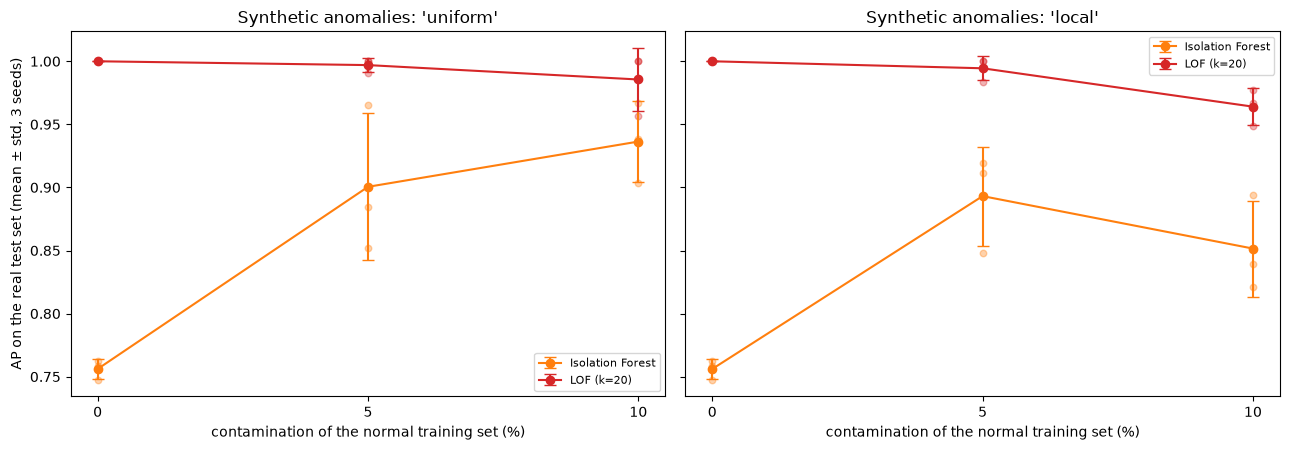

In [63]:
utils.plot_mouse_robustness(rob); plt.show()

**Explanation.**
- **LOF degrades slightly**: if injected (low-density) points become neighbours of the true anomalies, the density contrast decreases (**masking** effect). The effect (≤ 0.04) is of the same order as the spread across seeds.
- **IF improves** (+0.10 to +0.18, more than the std). This is counter-intuitive and does not prove that IF "benefits" from contamination. Plausible explanation: without contamination, no training point lies on the periphery; injected points **in the area of the true anomalies** partition that space more finely, which lowers the score of test normal points more than that of the anomalies.
- **Generator dependence**: at 10 %, IF gains 0.18 with `uniform` but 0.10 with `local`; LOF loses 0.014 vs 0.036. Synthetic anomalies here resemble the real ones, which favours IF; with another generator the conclusion could flip. **We cannot conclude that IF is more robust than LOF.**
- **Limitations**: 3 seeds, 10 real anomalies, a single 2-D dataset, two generators.

---
## 5.2 Explaining a few alerts with SHAP (Isolation Forest, Credit Card)
**Protocol.** Isolation Forest from Part 2 with its **frozen threshold**. Six **randomly drawn test observations** (fixed seed): 2 detected frauds, 2 false alarms, 2 missed frauds. Background: **50 training observations**. These explanations are not used for any tuning.

**Explained output.** `shap.TreeExplainer` does **not explain IF's final score** but the **mean path length E[h(x)]**: the longer it is, the more normal the observation (the score 2^(−E[h]/c) decreases with E[h]). Raw SHAP values therefore have the **opposite sign** to suspiciousness: we **multiply them by −1** (positive = more suspicious). Checks: additivity (base + Σ SHAP = E[h]) and comparison with `KernelExplainer` on the final score.

In [64]:
if_model = pool[FROZEN['Isolation Forest']['config']]['model']
shap_res = utils.shap_isolation_forest(if_model, cc['Xtr'], cc['Xte'], cc['yte'], FROZEN['Isolation Forest']['threshold'])
utils.report_shap_checks(shap_res)

,model E[h],base + Σ SHAP,mean E[h] background,anomaly score
detected fraud,11.850,11.850,23.742,0.594
detected fraud,10.938,10.938,23.742,0.619
false alarm,11.873,11.873,23.742,0.594
false alarm,10.631,10.631,23.742,0.627
missed fraud,17.640,17.640,23.742,0.461
missed fraud,23.393,23.393,23.742,0.358


Output explained by TreeExplainer = mean path length E[h(x)]; base + Σ SHAP = E[h(x)] for the 6 observations: True
Rank correlation (-tree SHAP vs kernel SHAP on the final score): [0.85 0.84 0.84 0.8  0.85 0.78]
Sign agreement on the 5 most influential features: [1. 1. 1. 1. 1. 1.]
Missing categories filled with other cases: none


,top 3 features
detected fraud (obs. 24065),"V14 (+1.54), V11 (+1.32), V18 (+1.13)"
detected fraud (obs. 5543),"V11 (+1.89), V14 (+1.50), V18 (+1.48)"
false alarm (obs. 8114),"V27 (+1.65), V1 (+1.24), V5 (+1.17)"
false alarm (obs. 16419),"Amount (+2.85), V5 (+2.00), V6 (+1.78)"
missed fraud (obs. 11505),"V16 (+0.99), V17 (+0.98), V12 (+0.94)"
missed fraud (obs. 14559),"V23 (+0.40), V27 (+0.38), V21 (+0.31)"


**Check results.**
- **Additivity verified** for the 6 observations: the explained output is indeed E[h] (e.g. 11.85 for a detected fraud, vs 23.74 on average over the background: isolated twice as fast).
- **Direction verified**: `KernelExplainer` on the final score gives the same signs for the top 5 features of all 6 observations (rank correlation 0.78 to 0.85).
- All three categories are represented.

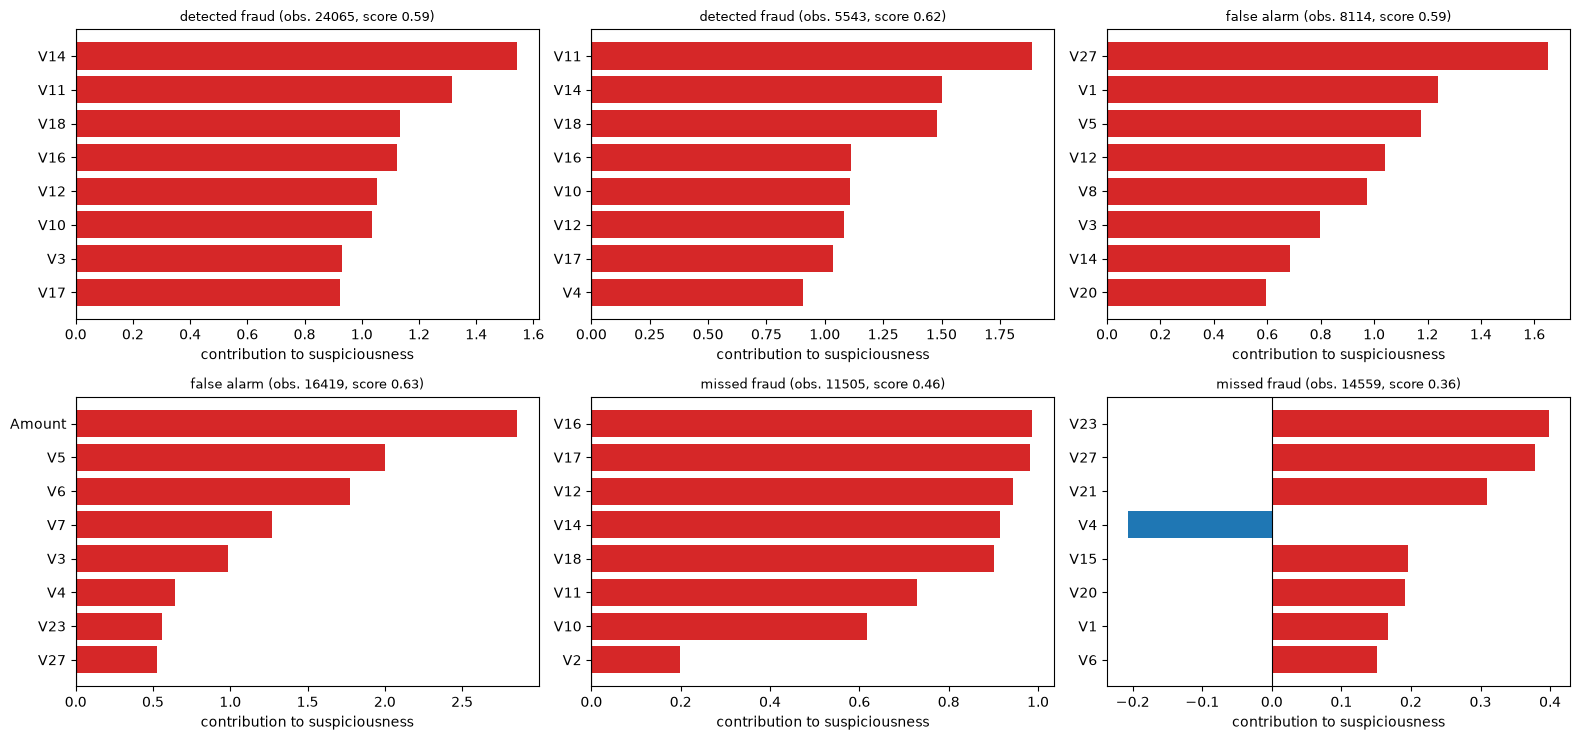

In [65]:
utils.plot_shap_if(shap_res); plt.show()

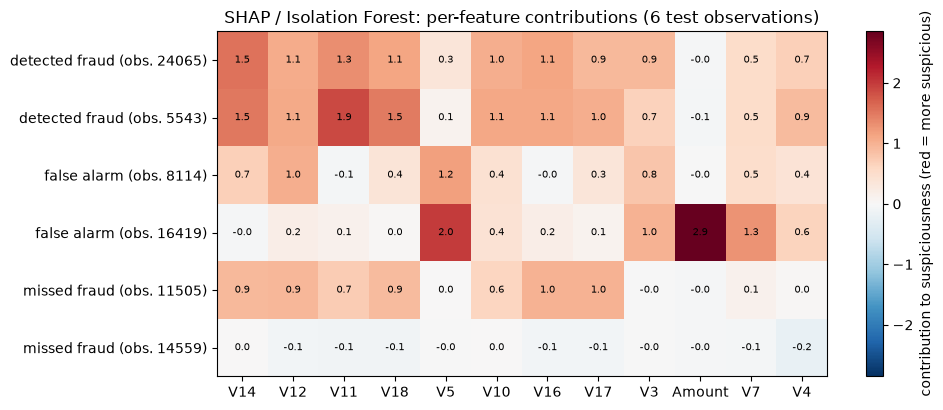

In [66]:
utils.plot_shap_heatmap(shap_res); plt.show()

**Reading the explanations** (positive = makes it more suspicious).

| Observation | Main features | Comment |
|---|---|---|
| Detected fraud 24065 | V14, V11, V18 | V14 very low (−8.5), V11 very high (+3.7) |
| Detected fraud 5543 | V11, V14, V18 | V14 = −11.2, V11 = +4.7 |
| False alarm 8114 | V27, V1, V5 | V14 very **high** (+4.95), V5 very low |
| False alarm 16419 | **Amount**, V5, V6 | amount of 5,317 (median 22) |
| Missed fraud 11505 | V16, V17, V12 | same signature as detected frauds, but weaker |
| Missed fraud 14559 | none (≤ 0.4) | entirely ordinary transaction |

- **Detected frauds**: V14 very low and V11 very high, along with V18, V16, V12, V17: the same features as with ECOD.
- **False alarms**: other features (Amount, V5, V27): atypical does not mean fraudulent. IF flags extremes **in both directions** (V14 very high for 8114), whereas frauds have very low V14: an unsupervised model does not know this direction.
- **Missed frauds**: one has the right signature but too weak to cross the threshold; the other has nothing extreme and cannot be seen by any extreme-value-based detector.

**What SHAP can and cannot do.** It **describes the model**: which features shortened or lengthened the path, relative to a 50-transaction background. It **does not prove causality**, and for V1..V28 (anonymised) **no business meaning** is possible; only `Amount` is interpretable. Six observations do not support any general conclusion.